# Notebook 02 · Análisis exploratorio con datos crudos
**Proyecto:** desnutrición crónica infantil con ENDES 2025 y XGBoost · IS-484 Inteligencia Artificial I · UNSCH

**Objetivo.** Conocer el dataset integrado en el notebook 01 **tal como viene**, sin limpiarlo, y aplicar sobre él los temas de las guías de laboratorio:

| Parte | Tema | Guía |
|---|---|---|
| 2-3 | Estructura, tipos de variable, calidad de datos (vacíos, códigos especiales, duplicados, inconsistencias, atípicos) | Semana 04 |
| 4-8 | Estadísticos descriptivos, variable objetivo, distribuciones, relaciones y correlación | Semana 03 y 05 |
| 9 | Codificación, escalado y división train/test (fuga de datos) | Semana 04 |
| 10 | Función de error y descenso de gradiente | Semana 03 |
| 11 | Regresión lineal simple y múltiple, métricas, Pipeline y comparación con Random Forest | Semana 05 |
| 12 | Hallazgos y plan de limpieza | — |

**Regla de este notebook:** ninguna celda modifica el dataset original. Cuando hace falta una versión "sin códigos especiales" o "escalada" para comparar, se crea en una **copia**. Los resultados de aquí son la línea base que se compara con los datos limpios en el notebook 04.

## 1. Configuración y carga

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 80)

AZUL, NARANJA, ROJO, GRIS, VERDE = "#4C78A8", "#F58518", "#E45756", "#9D9D9D", "#54A24B"

RAIZ = Path.cwd().parent if Path.cwd().name == "2 notebooks" else Path.cwd()
SALIDA = RAIZ / "3 datos_procesados"

df = pd.read_csv(SALIDA / "dataset_integrado_crudo.csv", dtype={"caseid": str, "hhid": str})
dic = pd.read_csv(SALIDA / "diccionario_variables.csv")

FEATURES = dic.loc[dic.rol == "feature", "nombre"].tolist()
CATEG = dic.loc[(dic.rol == "feature") & (dic.tipo == "categórica"), "nombre"].tolist()
NUM = [c for c in FEATURES if c not in CATEG]

# códigos especiales documentados en el diccionario (notebook 01): variable -> lista de códigos
CODIGOS = {r.nombre: [int(float(x)) for x in str(r.codigos_a_nan).split(",") if x.strip()]
           for r in dic.itertuples() if isinstance(r.codigos_a_nan, str) and r.codigos_a_nan.strip()}

print(f"Dataset: {df.shape[0]:,} niños × {df.shape[1]} columnas")
print(f"Features: {len(FEATURES)} ({len(NUM)} numéricas, {len(CATEG)} categóricas) | variables con códigos especiales: {len(CODIGOS)}")

Dataset: 18,841 niños × 50 columnas
Features: 42 (33 numéricas, 9 categóricas) | variables con códigos especiales: 20


## 2. Estructura del dataset
Primer paso de la guía de la Semana 04: ¿cuántas observaciones y variables hay, y de qué **tipo** es cada una? El tipo decide cómo se codifica y se escala después.

In [2]:
print("Observaciones (niños):", df.shape[0], "| Columnas:", df.shape[1])
print("Memoria:", round(df.memory_usage(deep=True).sum() / 1e6, 1), "MB")
print()
df.dtypes.value_counts().rename("columnas").to_frame()

Observaciones (niños): 18841 | Columnas: 50
Memoria: 9.4 MB



,columnas
float64,37
int64,11
str,2


In [3]:
# Clasificación de cada feature según la Semana 04 (continua, discreta, ordinal, binaria, nominal)
ORDINALES = ["quintil_riqueza", "nivel_educativo_madre", "nivel_anemia_nino", "tamano_percibido_nacer", "diarrea_2sem", "tos_2sem"]
CONTINUAS = ["edad_madre", "edad_primer_parto", "peso_nacer_g", "talla_madre_x10", "imc_madre_x100",
             "altitud_msnm", "hacinamiento", "intervalo_nac_previo_meses"]
DISCRETAS = ["edad_meses", "orden_nacimiento", "visitas_prenatales", "n_controles_cred", "meses_lactancia", "n_menores_5_hogar"]


def naturaleza(col):
    if col in CATEG:
        return "nominal"
    if col in ORDINALES:
        return "ordinal"
    if col in CONTINUAS:
        return "continua"
    if col in DISCRETAS:
        return "discreta"
    return "binaria"


tipos = pd.DataFrame({"variable": FEATURES})
tipos["naturaleza"] = tipos.variable.map(naturaleza)
tipos["bloque"] = tipos.variable.map(dict(zip(dic.nombre, dic.bloque)))
tipos["valores_distintos"] = tipos.variable.map(df[FEATURES].nunique())

resumen_tipos = (tipos.groupby("naturaleza").variable.agg(n="count", variables=lambda s: ", ".join(s))
                 .reindex(["continua", "discreta", "ordinal", "binaria", "nominal"]))
resumen_tipos

,n,variables
naturaleza,,
continua,8,"intervalo_nac_previo_meses, peso_nacer_g, edad_madre, edad_primer_parto, tal..."
discreta,6,"edad_meses, orden_nacimiento, visitas_prenatales, meses_lactancia, n_control..."
ordinal,6,"nivel_anemia_nino, tamano_percibido_nacer, diarrea_2sem, tos_2sem, nivel_edu..."
binaria,13,"sexo_nino, hierro_embarazo, lactancia_exclusiva_6m, hierro_jarabe_7d, micron..."
nominal,9,"lugar_parto, lengua_materna_madre, departamento, region_natural, tipo_servic..."


**Lectura:** el dataset tiene 18 841 niños y 50 columnas: 42 *features*, 4 de apoyo, 2 insumos y 2 objetivos. De las 42 features, 8 son continuas (peso al nacer, talla e IMC de la madre, altitud…), 6 discretas (edad en meses, orden de nacimiento, número de controles…), 6 ordinales (quintil de riqueza, educación de la madre…), 13 binarias y 9 nominales. Casi todo está guardado como número: lo que cambia es **qué significa** ese número, y eso decide cómo se trata (sección 9).

## 3. Calidad de los datos
Un dataset real rara vez llega limpio (Semana 04). Se diagnostican cinco problemas **sin corregirlos**: vacíos, códigos especiales, duplicados, inconsistencias y atípicos. En ENDES el problema más traicionero es el segundo: los "no sabe / no aplica" vienen como **números** (`9998`, `99`, `8`…) y no como vacíos.

### 3.1 Valores faltantes (`NaN`)

In [4]:
vacios = df[FEATURES].isna().mean().mul(100).sort_values(ascending=False)
tabla_vacios = pd.DataFrame({"vacíos": df[FEATURES].isna().sum(), "% vacíos": vacios.round(1)}).sort_values("% vacíos", ascending=False)
print("Features sin ningún vacío:", int((tabla_vacios["vacíos"] == 0).sum()), "de", len(FEATURES))
tabla_vacios[tabla_vacios["vacíos"] > 0]

Features sin ningún vacío: 25 de 42


,vacíos,% vacíos
lactancia_exclusiva_6m,8656,45.9
intervalo_nac_previo_meses,6536,34.7
visitas_prenatales,1908,10.1
hierro_embarazo,1908,10.1
hierro_jarabe_7d,897,4.8
micronutrientes_polvo_7d,897,4.8
seguro_nino_sis,730,3.9
nivel_anemia_nino,552,2.9
edad_meses,552,2.9
material_piso,292,1.5


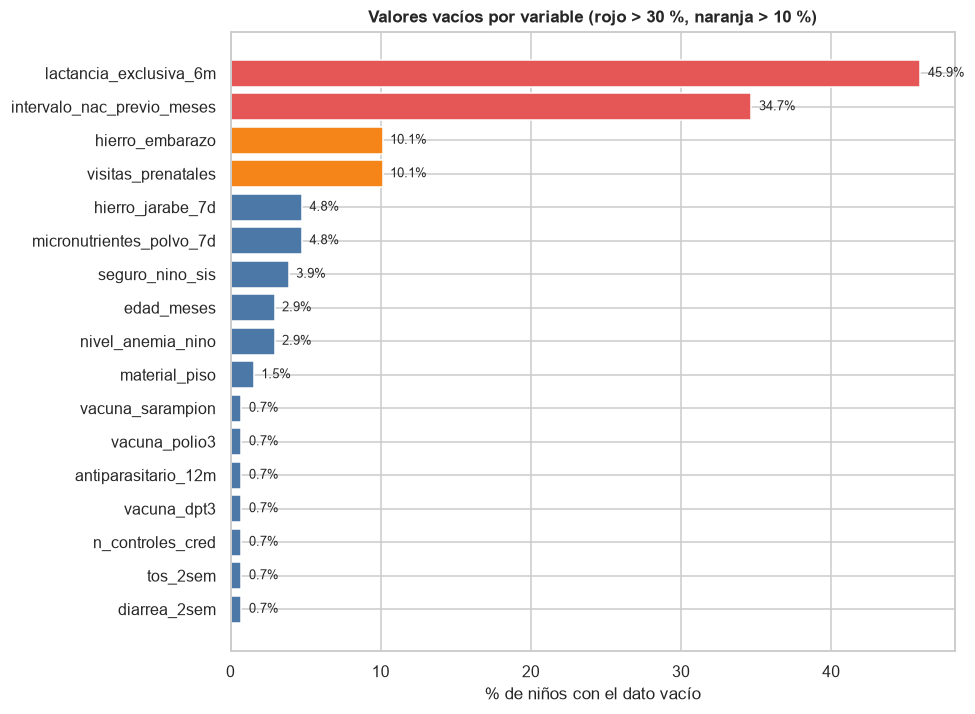

In [5]:
con_vacios = vacios[vacios > 0]
fig, ax = plt.subplots(figsize=(9, 0.32 * len(con_vacios) + 1.2))
colores = [ROJO if v > 30 else NARANJA if v > 10 else AZUL for v in con_vacios.values]
ax.barh(con_vacios.index[::-1], con_vacios.values[::-1], color=colores[::-1])
for i, v in enumerate(con_vacios.values[::-1]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8.5)
ax.set_xlabel("% de niños con el dato vacío")
ax.set_title("Valores vacíos por variable (rojo > 30 %, naranja > 10 %)")
plt.tight_layout()
plt.show()

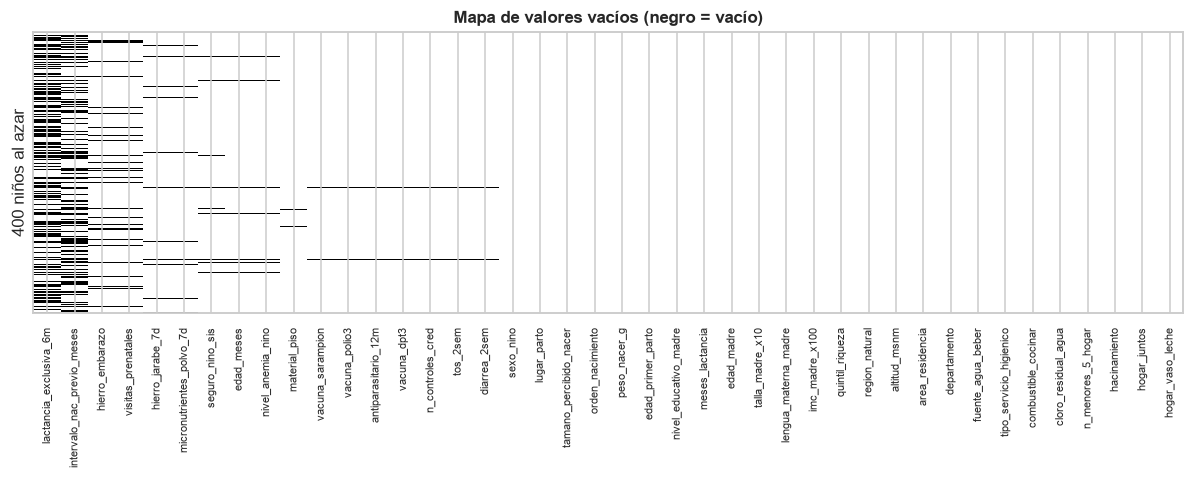

In [6]:
# Mapa de vacíos: cada columna es una variable y cada fila un niño (muestra de 400). Negro = vacío
muestra = df[FEATURES].isna().sample(400, random_state=42)
orden_cols = vacios.index.tolist()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.imshow(muestra[orden_cols].values, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_xticks(range(len(orden_cols)))
ax.set_xticklabels(orden_cols, rotation=90, fontsize=7)
ax.set_yticks([])
ax.set_ylabel("400 niños al azar")
ax.set_title("Mapa de valores vacíos (negro = vacío)")
plt.tight_layout()
plt.show()

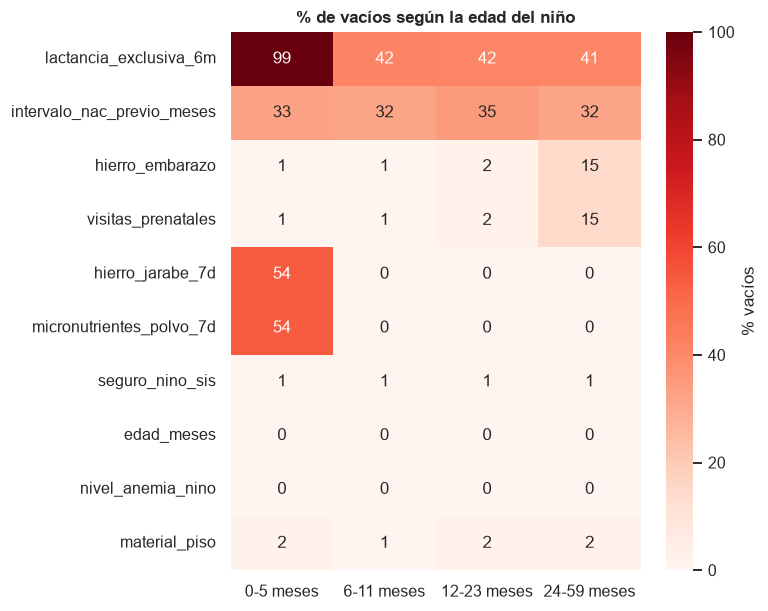

In [7]:
# ¿Los vacíos dependen de la edad del niño? (vacíos "por diseño")
grupo_edad = pd.cut(df["edad_meses"], [-1, 5, 11, 23, 59], labels=["0-5 meses", "6-11 meses", "12-23 meses", "24-59 meses"])
cols_vac = vacios[vacios > 1].index.tolist()
vac_edad = df.groupby(grupo_edad, observed=True)[cols_vac].apply(lambda x: x.isna().mean().mul(100)).T

fig, ax = plt.subplots(figsize=(7, 0.42 * len(cols_vac) + 1.5))
sns.heatmap(vac_edad, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% vacíos"}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("% de vacíos según la edad del niño")
plt.tight_layout()
plt.show()

**Comprobación:** `visitas_prenatales` y `hierro_embarazo` tienen exactamente 1 908 vacíos, el mismo número de niños que comparten madre con un hermano (18 841 niños − 16 933 madres). Se comprueba si esos vacíos son los hijos que **no** son el menor de su madre.

In [8]:
es_menor = df.groupby("caseid")["edad_meses"].transform("min") == df["edad_meses"]
print(f"Niños − madres distintas = {len(df) - df['caseid'].nunique():,} | vacíos de visitas_prenatales = {int(df['visitas_prenatales'].isna().sum()):,}")
(df.groupby(es_menor.map({True: "hijo menor de la madre", False: "tiene un hermano menor"}))[["visitas_prenatales", "hierro_embarazo"]]
   .apply(lambda x: x.isna().mean().mul(100)).round(1).rename_axis("").add_suffix(" (% vacío)"))

Niños − madres distintas = 1,908 | vacíos de visitas_prenatales = 1,908


,visitas_prenatales (% vacío),hierro_embarazo (% vacío)
,,
hijo menor de la madre,0.9,0.9
tiene un hermano menor,80.7,80.7


**Lectura:** 25 de las 42 features están completas. Los vacíos grandes son **por diseño**, no errores: `lactancia_exclusiva_6m` (46 %) casi no existe antes de los 6 meses y falta también en ≈ 40 % de los mayores; `intervalo_nac_previo_meses` (35 %) está vacío en los primogénitos; `visitas_prenatales` y `hierro_embarazo` (10 %) solo se preguntan por el **hijo menor de cada madre** (la comprobación de abajo lo confirma); el hierro en jarabe y los micronutrientes solo tienen valor desde los 6 meses; y 552 niños (2.9 %) no tienen edad ni anemia registradas (niños no medidos).

### 3.2 Códigos especiales disfrazados de datos
El diccionario de ENDES reserva números para "no sabe", "no se pesó" o "no aplica". Si no se convierten en `NaN`, el modelo los lee como cantidades reales. Se cuentan con la tabla de códigos del notebook 01.

In [9]:
# El código 94 de meses_lactancia (nunca amamantó) se recodifica a 0, no a NaN: no se cuenta aquí
filas = []
for var, cods in CODIGOS.items():
    n = int(df[var].isin(cods).sum())
    if n:
        filas.append({"variable": var, "códigos": cods, "valores afectados": n,
                      "% del total": round(100 * n / len(df), 2)})
codigos_tabla = pd.DataFrame(filas).sort_values("valores afectados", ascending=False).reset_index(drop=True)
codigos_tabla

,variable,códigos,valores afectados,% del total
0,cloro_residual_agua,"[6, 9]",2788,14.80
1,nivel_anemia_nino,[9],1590,8.44
2,peso_nacer_g,"[9996, 9998]",466,2.47
3,vacuna_dpt3,[8],370,1.96
4,imc_madre_x100,"[9998, 9999]",354,1.88
5,talla_madre_x10,[9999],352,1.87
6,vacuna_polio3,[8],267,1.42
7,n_controles_cred,[98],191,1.01
8,vacuna_sarampion,[8],94,0.50
9,visitas_prenatales,[98],20,0.11


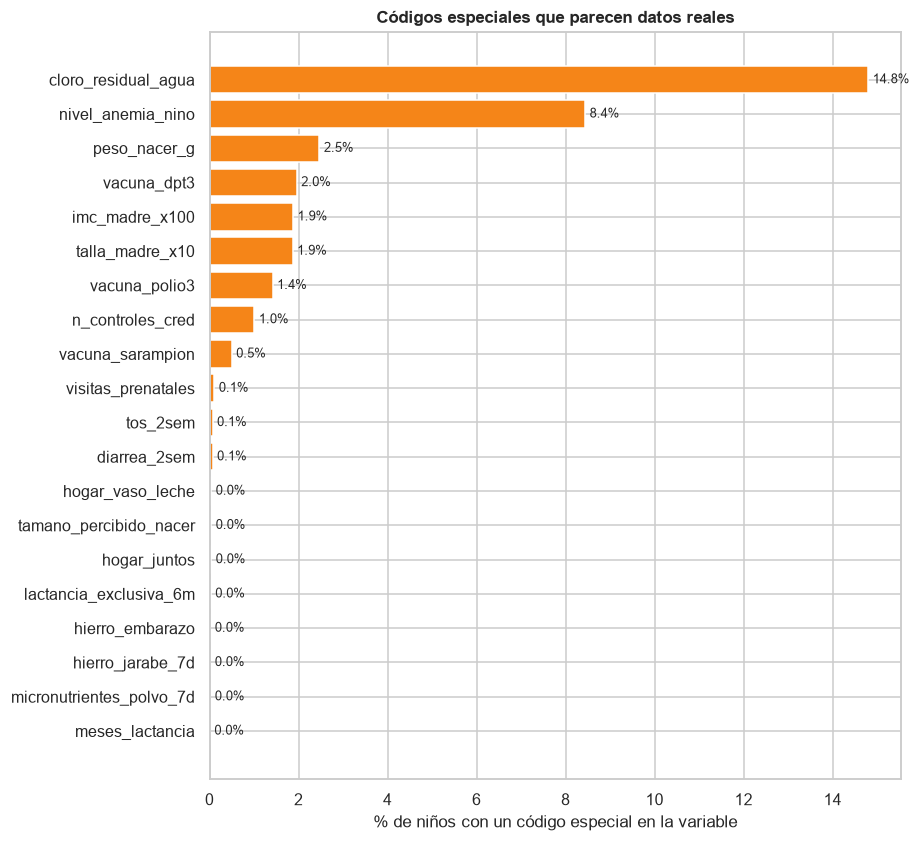

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 0.33 * len(codigos_tabla) + 1.2))
ax.barh(codigos_tabla["variable"][::-1], codigos_tabla["% del total"][::-1], color=NARANJA)
for i, v in enumerate(codigos_tabla["% del total"][::-1]):
    ax.text(v + 0.1, i, f"{v:.1f}%", va="center", fontsize=8.5)
ax.set_xlabel("% de niños con un código especial en la variable")
ax.set_title("Códigos especiales que parecen datos reales")
plt.tight_layout()
plt.show()

**Por qué importa:** se comparan dos variables con y sin sus códigos especiales (en una copia).

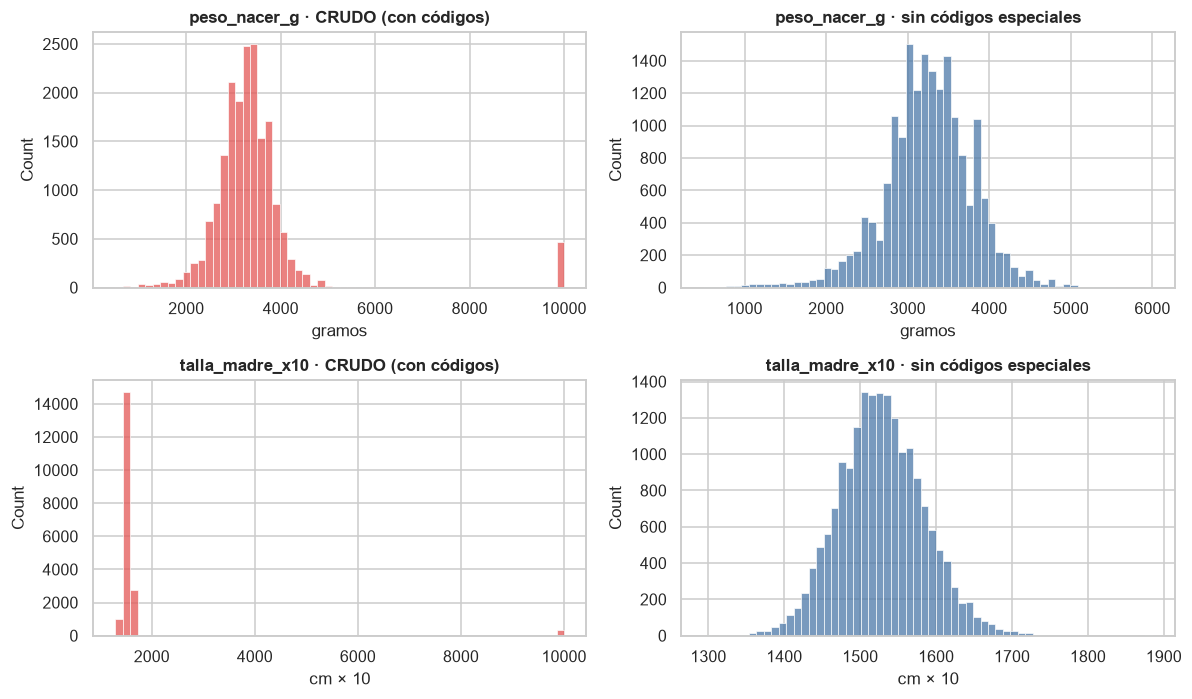

,media cruda,media sin códigos,distorsión %
vacuna_dpt3,1.0,0.9,15.5
nivel_anemia_nino,4.0,3.6,13.3
vacuna_polio3,1.0,0.9,10.6
talla_madre_x10,1685.8,1527.5,10.4
n_controles_cred,16.8,15.9,5.3
peso_nacer_g,3411.4,3244.4,5.1
imc_madre_x100,2975.1,2840.6,4.7
vacuna_sarampion,0.9,0.9,3.9
diarrea_2sem,0.2,0.2,2.5
visitas_prenatales,9.4,9.3,1.1


In [11]:
def sin_codigos(serie):
    return serie.where(~serie.isin(CODIGOS.get(serie.name, [])))


fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for fila, (var, unidad) in enumerate([("peso_nacer_g", "gramos"), ("talla_madre_x10", "cm × 10")]):
    sns.histplot(df[var].dropna(), bins=60, color=ROJO, ax=axes[fila, 0])
    axes[fila, 0].set_title(f"{var} · CRUDO (con códigos)")
    axes[fila, 0].set_xlabel(unidad)
    sns.histplot(sin_codigos(df[var]).dropna(), bins=60, color=AZUL, ax=axes[fila, 1])
    axes[fila, 1].set_title(f"{var} · sin códigos especiales")
    axes[fila, 1].set_xlabel(unidad)
plt.tight_layout()
plt.show()

comparacion = pd.DataFrame({
    "media cruda": [df[v].mean() for v in CODIGOS if v in NUM],
    "media sin códigos": [sin_codigos(df[v]).mean() for v in CODIGOS if v in NUM],
}, index=[v for v in CODIGOS if v in NUM])
comparacion["distorsión %"] = ((comparacion["media cruda"] / comparacion["media sin códigos"] - 1) * 100).round(1)
comparacion.sort_values("distorsión %", ascending=False).round(1).head(10)

**Lectura:** veinte variables llevan códigos especiales. Pesan más `cloro_residual_agua` (14.8 %: el 9 es "no se pudo medir" y el 6 no figura en el diccionario), `nivel_anemia_nino` (8.4 %: no medida, casi todos menores de 6 meses) y `peso_nacer_g` (2.5 %). El efecto es enorme: sin convertirlos, la talla media de la madre sale 168.6 cm en lugar de 152.8 cm (+10 %) y el peso medio al nacer 3 411 g en lugar de 3 244 g. En los histogramas se ve como un pico aislado en 9996-9999 que no tiene nada que ver con la realidad.

### 3.3 Duplicados

In [12]:
dup_exactas = int(df.duplicated().sum())
dup_features = int(df.duplicated(FEATURES, keep=False).sum())
por_madre = df.groupby("caseid").size()

print(f"Filas completamente duplicadas              : {dup_exactas}")
print(f"Niños con las 42 features idénticas a otro  : {dup_features}")
print(f"Madres distintas                            : {por_madre.shape[0]:,} (para {len(df):,} niños)")
print()
por_madre.value_counts().sort_index().rename("madres").to_frame().rename_axis("niños por madre")

Filas completamente duplicadas              : 0
Niños con las 42 features idénticas a otro  : 0
Madres distintas                            : 16,933 (para 18,841 niños)



,madres
niños por madre,
1,15097
2,1764
3,72


In [13]:
# Si hay niños con features idénticas, ¿son hermanos (misma madre) o coincidencias?
gemelos = df[df.duplicated(FEATURES, keep=False)].sort_values(FEATURES)
print("De esas filas idénticas, las que comparten madre (mellizos u hogares con hermanos iguales):",
      int(gemelos.duplicated("caseid", keep=False).sum()))
if len(gemelos) == 0:
    print("Ninguna fila repetida: no hay duplicados que eliminar ni mellizos con datos idénticos.")
else:
    display(gemelos[["caseid", "edad_meses", "sexo_nino", "orden_nacimiento", "peso_nacer_g", "quintil_riqueza", "haz"]].head(6))

De esas filas idénticas, las que comparten madre (mellizos u hogares con hermanos iguales): 0
Ninguna fila repetida: no hay duplicados que eliminar ni mellizos con datos idénticos.


**Lectura:** no hay filas duplicadas ni niños con las 42 features idénticas: no hay nada que eliminar. Sí hay **estructura de grupo**: 16 933 madres para 18 841 niños; 1 764 madres tienen 2 niños y 72 tienen 3 (1 908 niños, el 10 %, tienen un hermano en la muestra). Los hermanos comparten madre, hogar y conglomerado, así que no son independientes entre sí: una razón más para dividir train/test por grupos.

### 3.4 Inconsistencias en los códigos
En Semana 04 las inconsistencias eran de texto ("Mañana" vs "mañana"). Aquí todo son **códigos numéricos**, así que la inconsistencia equivale a un código **fuera de los permitidos** por el diccionario INEI. Se comparan los valores observados con los esperados.

In [14]:
VALIDOS = {
    "sexo_nino": [1, 2], "area_residencia": [1, 2], "region_natural": [1, 2, 3, 4], "quintil_riqueza": [1, 2, 3, 4, 5],
    "nivel_educativo_madre": [0, 1, 2, 3], "nivel_anemia_nino": [1, 2, 3, 4, 9], "tamano_percibido_nacer": [1, 2, 3, 4, 5, 8],
    "lugar_parto": [11, 12, 21, 22, 23, 24, 25, 26, 27, 31, 32, 41, 42, 96],
    "tipo_servicio_higienico": [11, 12, 21, 22, 23, 24, 31, 32, 96],
    "fuente_agua_beber": [11, 12, 13, 21, 22, 41, 43, 51, 61, 71, 96],
    "material_piso": [11, 21, 31, 32, 33, 34, 96],
    "combustible_cocinar": list(range(1, 12)) + [95, 96],
    "cloro_residual_agua": [1, 2, 3, 4, 5, 9],
    "lengua_materna_madre": list(range(1, 14)),
    "departamento": list(range(1, 26)),
    "hierro_embarazo": [0, 1, 8], "antiparasitario_12m": [0, 1], "seguro_nino_sis": [0, 1],
    "lactancia_exclusiva_6m": [1, 2, 8], "hierro_jarabe_7d": [1, 2, 8], "micronutrientes_polvo_7d": [1, 2, 8],
    "diarrea_2sem": [0, 1, 2, 8], "tos_2sem": [0, 1, 2, 8],
    "vacuna_dpt3": [0, 1, 2, 3, 8], "vacuna_polio3": [0, 1, 2, 3, 8], "vacuna_sarampion": [0, 1, 2, 3, 8],
    "hogar_juntos": [1, 2, 8], "hogar_vaso_leche": [1, 2, 8],
}
filas = []
for var, ok in VALIDOS.items():
    fuera = df[var].dropna()[~df[var].dropna().isin(ok)]
    if len(fuera):
        filas.append({"variable": var, "códigos fuera del diccionario": sorted(fuera.unique().tolist()), "niños afectados": len(fuera)})
inconsistentes = pd.DataFrame(filas)
print(f"Variables revisadas: {len(VALIDOS)} | con códigos inesperados: {len(inconsistentes)}")
inconsistentes if len(inconsistentes) else "Todos los códigos observados figuran en el diccionario."

Variables revisadas: 28 | con códigos inesperados: 1


,variable,códigos fuera del diccionario,niños afectados
0,cloro_residual_agua,[6.0],1178


**Lectura:** de las 28 variables revisadas, solo `cloro_residual_agua` trae códigos fuera del diccionario INEI: el código 6 aparece en 1 178 niños (6.3 %) y no se sabe qué significa, así que se tratará como `NaN`. En todas las demás los datos respetan el diccionario (no hay, por ejemplo, sexos distintos de 1 y 2 ni departamentos fuera de 1-25).

### 3.5 Valores atípicos
Dos métodos de la Semana 04: **reglas lógicas** (cuando el problema dice qué valores son imposibles) y **rango intercuartílico (RIC)** (método general, fuera de [Q1 − 1.5·RIC, Q3 + 1.5·RIC]).

In [15]:
# Reglas lógicas: ¿cuántos niños las incumplen? (los códigos especiales ya contados en 3.2 se excluyen de cada regla)
d_ = df
reglas = [
    ("edad_madre fuera de 12-49 años",                    ~d_.edad_madre.between(12, 49) & d_.edad_madre.notna()),
    ("edad al primer parto menor de 10 años",             d_.edad_primer_parto < 10),
    ("edad al primer parto mayor que la edad de la madre", d_.edad_primer_parto > d_.edad_madre),
    ("peso al nacer fuera de 500-6 000 g (sin códigos)",  ~d_.peso_nacer_g.between(500, 6000) & ~d_.peso_nacer_g.isin([9996, 9998]) & d_.peso_nacer_g.notna()),
    ("talla de la madre fuera de 130-190 cm (sin código)", ~d_.talla_madre_x10.between(1300, 1900) & (d_.talla_madre_x10 != 9999) & d_.talla_madre_x10.notna()),
    ("IMC de la madre fuera de 12-50 (sin códigos)",      ~d_.imc_madre_x100.between(1200, 5000) & ~d_.imc_madre_x100.isin([9998, 9999]) & d_.imc_madre_x100.notna()),
    ("más de 25 controles prenatales (sin código 98)",    (d_.visitas_prenatales > 25) & (d_.visitas_prenatales != 98)),
    ("meses de lactancia mayores que la edad del niño",   (d_.meses_lactancia > d_.edad_meses) & ~d_.meses_lactancia.isin([94, 98])),
    ("intervalo entre hijos menor de 9 meses",            d_.intervalo_nac_previo_meses < 9),
    ("hogar con 0 menores de 5 años (hay un niño)",       d_.n_menores_5_hogar == 0),
    ("hacinamiento mayor a 8 personas por dormitorio",    d_.hacinamiento > 8),
    ("altitud mayor a 4 500 m",                           d_.altitud_msnm > 4500),
    ("puntaje Z (haz) fuera de ±6",                       ~d_.haz.between(-6, 6) & d_.haz.notna()),
]
tabla_reglas = pd.DataFrame([{"regla": n, "niños que la incumplen": int(m.sum()), "%": round(100 * m.mean(), 2)} for n, m in reglas])
tabla_reglas

,regla,niños que la incumplen,%
0,edad_madre fuera de 12-49 años,0,0.00
1,edad al primer parto menor de 10 años,0,0.00
2,edad al primer parto mayor que la edad de la madre,0,0.00
3,peso al nacer fuera de 500-6 000 g (sin códigos),0,0.00
4,talla de la madre fuera de 130-190 cm (sin código),1,0.01
5,IMC de la madre fuera de 12-50 (sin códigos),18,0.10
6,más de 25 controles prenatales (sin código 98),0,0.00
7,meses de lactancia mayores que la edad del niño,3,0.02
8,intervalo entre hijos menor de 9 meses,0,0.00
9,hogar con 0 menores de 5 años (hay un niño),45,0.24


In [16]:
# Método RIC sobre las variables continuas (datos crudos)
filas = []
for var in CONTINUAS:
    s = df[var].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    ric = q3 - q1
    inf, sup = q1 - 1.5 * ric, q3 + 1.5 * ric
    fuera = s[(s < inf) | (s > sup)]
    filas.append({"variable": var, "Q1": q1, "Q3": q3, "RIC": ric, "límite inf.": inf, "límite sup.": sup,
                  "atípicos": len(fuera), "% atípicos": round(100 * len(fuera) / len(s), 2),
                  "de ellos, códigos especiales": int(fuera.isin(CODIGOS.get(var, [])).sum())})
tabla_ric = pd.DataFrame(filas).set_index("variable").round(1)
tabla_ric

,Q1,Q3,RIC,límite inf.,límite sup.,atípicos,% atípicos,"de ellos, códigos especiales"
variable,,,,,,,,
edad_madre,26.0,36.0,10.0,11.0,51.0,0,0.0,0
edad_primer_parto,18.0,24.0,6.0,9.0,33.0,521,2.8,0
peso_nacer_g,2950.0,3615.0,665.0,1952.5,4612.5,943,5.0,466
talla_madre_x10,1491.0,1566.0,75.0,1378.5,1678.5,546,2.9,352
imc_madre_x100,2490.0,3167.0,677.0,1474.5,4182.5,614,3.3,354
altitud_msnm,113.0,2577.0,2464.0,-3583.0,6273.0,0,0.0,0
hacinamiento,2.0,3.0,1.0,0.5,4.5,1586,8.4,0
intervalo_nac_previo_meses,42.0,104.0,62.0,-51.0,197.0,222,1.8,0


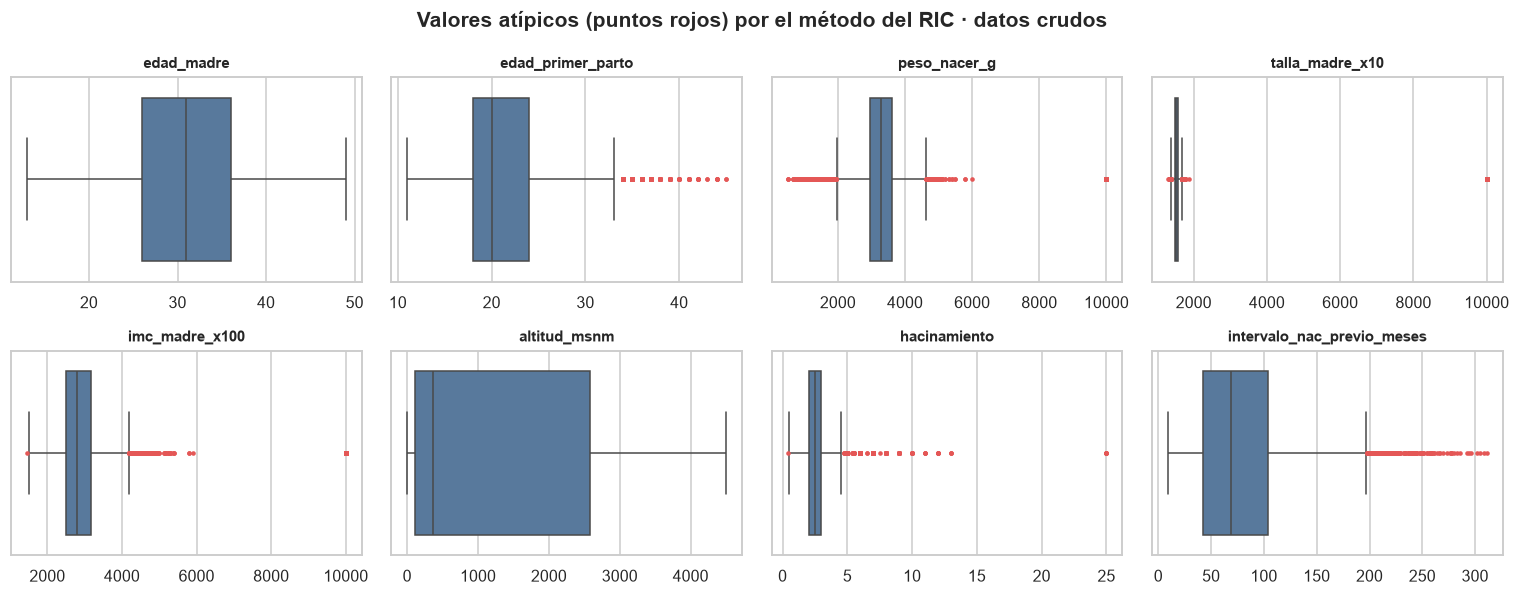

In [17]:
# Diagramas de caja de las variables continuas (crudo): los códigos 9996-9999 aparecen como puntos lejanísimos
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
for ax, var in zip(axes.ravel(), CONTINUAS):
    sns.boxplot(x=df[var], ax=ax, color=AZUL, fliersize=2, flierprops={"markerfacecolor": ROJO, "markeredgecolor": ROJO})
    ax.set_title(var, fontsize=10)
    ax.set_xlabel("")
fig.suptitle("Valores atípicos (puntos rojos) por el método del RIC · datos crudos", fontweight="bold")
plt.tight_layout()
plt.show()

**Lectura:** las reglas lógicas casi no detectan problemas: 45 hogares dicen no tener menores de 5 años aunque el niño vive ahí (0.24 %), 69 tienen más de 8 personas por dormitorio, hay 18 IMC extremos y 3 niños con más meses de lactancia que su edad. El método del RIC, en cambio, marca muchos "atípicos", pero **la mayoría no son errores**: de los 943 pesos al nacer atípicos, 466 son los códigos 9996 y 9998 y el resto son bebés muy grandes o muy pequeños reales (justo los que interesan); de las 546 tallas maternas atípicas, 352 son el código 9999. Moraleja: primero se convierten los códigos especiales y recién después se aplica el RIC; borrar atípicos a ciegas eliminaría casos reales de bajo peso al nacer.

## 4. Estadísticos descriptivos
Tal como pide la Semana 03: media, mediana, moda, rango, varianza y desviación estándar, más asimetría. Se calculan sobre los datos **crudos**, así que las variables con códigos especiales salen distorsionadas (se marcan con ⚠).

In [18]:
cols_desc = CONTINUAS + DISCRETAS + ["haz"]
filas = []
for var in cols_desc:
    s = df[var].dropna()
    filas.append({
        "variable": var + (" ⚠" if var in CODIGOS else ""),
        "n": len(s), "media": s.mean(), "mediana": s.median(), "moda": s.mode().iloc[0],
        "mínimo": s.min(), "máximo": s.max(), "rango": s.max() - s.min(),
        "varianza": s.var(), "desv. estándar": s.std(), "asimetría": s.skew(),
    })
descriptivos = pd.DataFrame(filas).set_index("variable").round(2)
descriptivos

,n,media,mediana,moda,mínimo,máximo,rango,varianza,desv. estándar,asimetría
variable,,,,,,,,,,
edad_madre,18841,30.92,31.00,32.00,13.00,49.00,36.00,48.59,6.97,0.04
edad_primer_parto,18841,21.34,20.00,19.00,11.00,45.00,34.00,26.04,5.10,1.05
peso_nacer_g ⚠,18841,3411.42,3280.00,3200.00,500.00,9998.00,9498.00,1397928.92,1182.34,4.14
talla_madre_x10 ⚠,18841,1685.82,1527.00,9999.00,1294.00,9999.00,8705.00,1318910.89,1148.44,7.08
imc_madre_x100 ⚠,18841,2975.06,2808.00,9999.00,1453.00,9999.00,8546.00,1202971.24,1096.80,4.92
altitud_msnm,18841,1197.18,364.00,27.00,1.00,4500.00,4499.00,1894880.07,1376.55,0.84
hacinamiento,18841,2.75,2.50,2.00,0.38,25.00,24.62,1.79,1.34,3.32
intervalo_nac_previo_meses,12305,77.76,69.00,26.00,9.00,311.00,302.00,2093.72,45.76,1.02
edad_meses,18289,30.46,31.00,41.00,0.00,59.00,59.00,280.94,16.76,-0.03


**Lectura:** con los códigos incluidos, las estadísticas engañan: el peso al nacer llega a 9 998 g, con asimetría 4.1 y desviación de 1 182 g; en la talla de la madre la **moda es 9999** (el valor más repetido es un código) y la media (168.6 cm) está 16 cm por encima de la mediana (152.7 cm). Las variables sin códigos son coherentes: la madre tiene en promedio 31 años y 21 al primer parto, y el `haz` tiene media −0.83 y desviación 1.03, casi simétrico (asimetría −0.06) entre −5.7 y +4.0: en promedio los niños están casi un desvío por debajo de la referencia OMS.

## 5. Variable objetivo
Dos objetivos (notebook 01): **`haz`** (puntaje Z de talla para la edad, continuo, para regresión) y **`desnutricion_cronica`** (1 si `haz < -2`, para clasificación con XGBoost). Se analizan solo los niños con objetivo válido (los demás no se pueden usar para entrenar).

Niños totales: 18,841 | con objetivo válido: 18,023 | sin objetivo: 818
Prevalencia de desnutrición crónica: 11.9 %


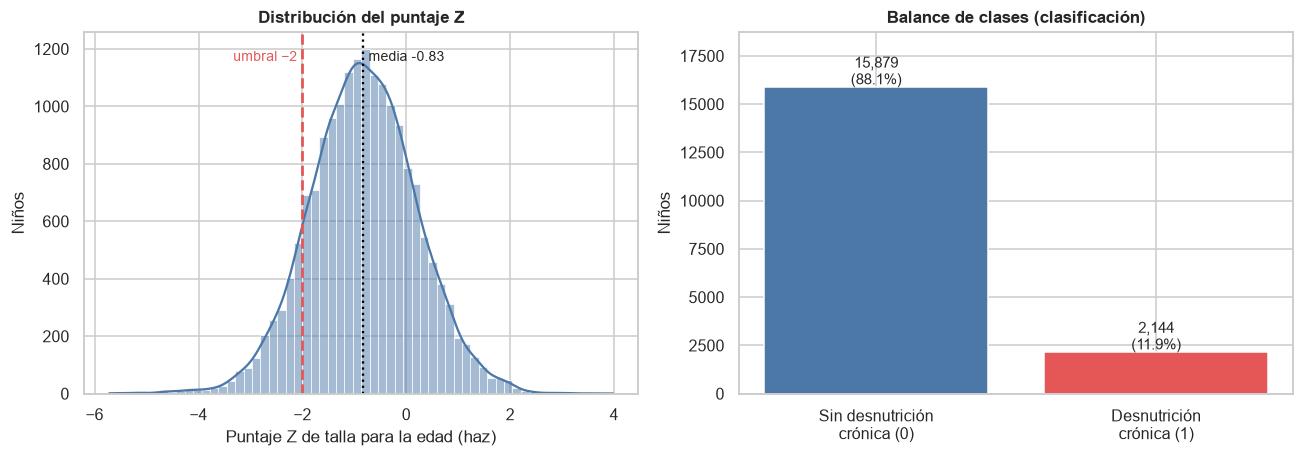

In [19]:
dr = df[df["haz"].notna()].reset_index(drop=True)
dr["desnutricion_cronica"] = dr["desnutricion_cronica"].astype(int)
PREV = dr["desnutricion_cronica"].mean() * 100

print(f"Niños totales: {len(df):,} | con objetivo válido: {len(dr):,} | sin objetivo: {len(df) - len(dr):,}")
print(f"Prevalencia de desnutrición crónica: {PREV:.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
sns.histplot(dr["haz"], bins=60, kde=True, color=AZUL, ax=axes[0])
axes[0].axvline(-2, color=ROJO, ls="--", lw=1.8)
axes[0].axvline(dr["haz"].mean(), color="black", ls=":", lw=1.5)
axes[0].text(-2.1, axes[0].get_ylim()[1] * 0.92, "umbral −2", color=ROJO, ha="right", fontsize=9)
axes[0].text(dr["haz"].mean() + 0.1, axes[0].get_ylim()[1] * 0.92, f"media {dr['haz'].mean():.2f}", fontsize=9)
axes[0].set_xlabel("Puntaje Z de talla para la edad (haz)")
axes[0].set_ylabel("Niños")
axes[0].set_title("Distribución del puntaje Z")

conteo = dr["desnutricion_cronica"].value_counts().sort_index()
barras = axes[1].bar(["Sin desnutrición\ncrónica (0)", "Desnutrición\ncrónica (1)"], conteo.values, color=[AZUL, ROJO])
for b, v in zip(barras, conteo.values):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 150, f"{v:,}\n({100 * v / len(dr):.1f}%)", ha="center", fontsize=10)
axes[1].set_ylim(0, conteo.max() * 1.18)
axes[1].set_ylabel("Niños")
axes[1].set_title("Balance de clases (clasificación)")
plt.tight_layout()
plt.show()

**Lectura:** de 18 841 niños, 18 023 tienen puntaje Z válido. El `haz` forma casi una campana desplazada a la izquierda de la referencia (media −0.83), y el umbral de −2 deja por debajo al **11.9 %** (2 144 niños). Es un problema **desbalanceado** (1 de cada 8): decir siempre "no" acertaría el 88 %, por eso la exactitud no sirve. Se evaluará con AUC-PR, recall y F1, y XGBoost usará `scale_pos_weight`.

### 5.1 ¿Quiénes están más afectados?
Prevalencia de desnutrición crónica (% de niños con `haz < -2`) según los factores principales. La línea punteada es la prevalencia nacional.

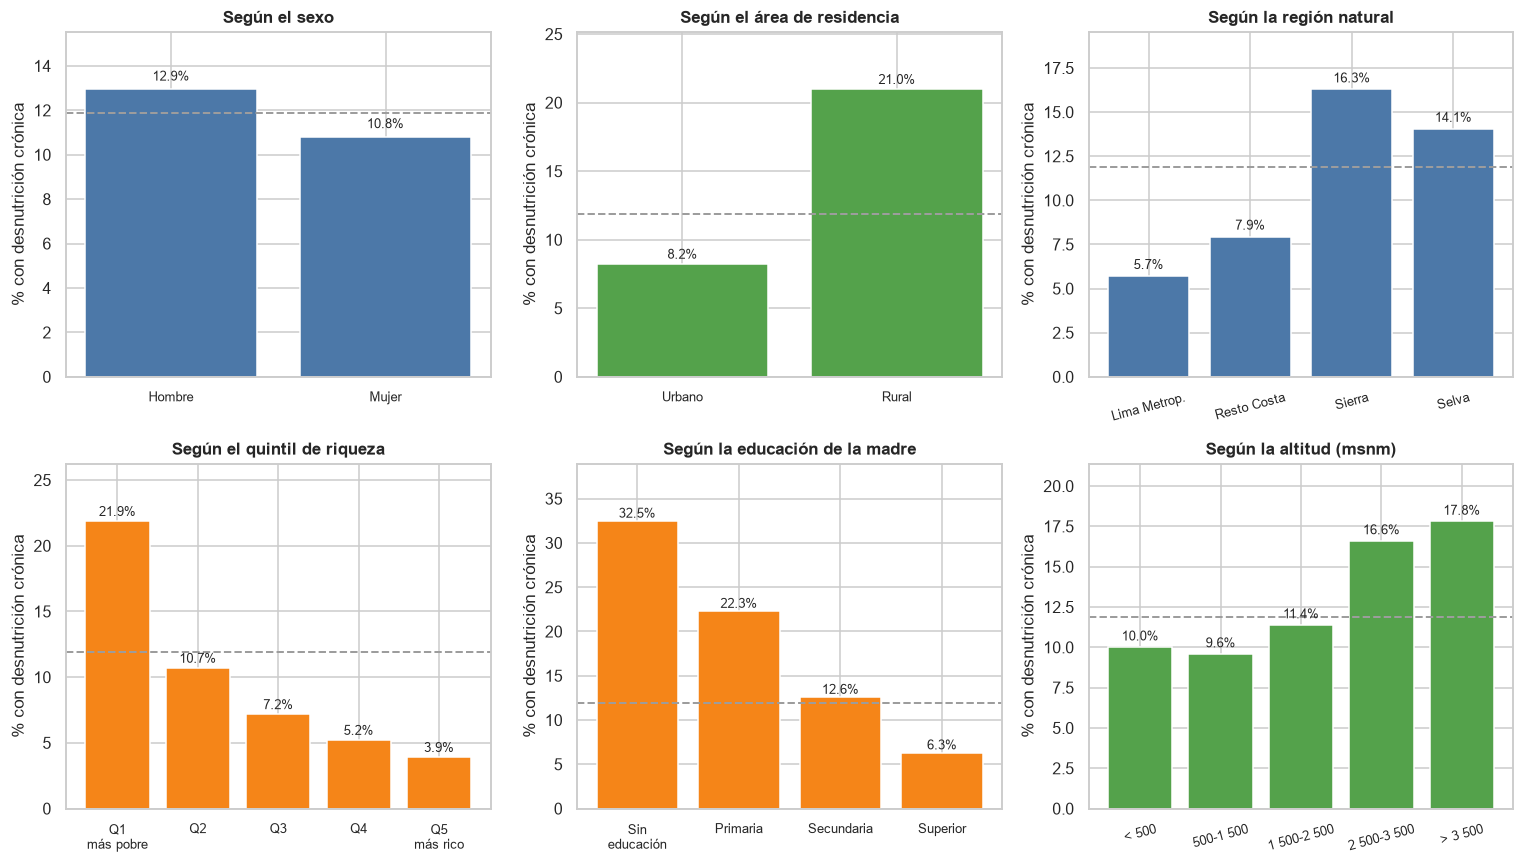

In [20]:
ETQ = {
    "sexo_nino": {1: "Hombre", 2: "Mujer"},
    "area_residencia": {1: "Urbano", 2: "Rural"},
    "region_natural": {1: "Lima Metrop.", 2: "Resto Costa", 3: "Sierra", 4: "Selva"},
    "quintil_riqueza": {1: "Q1\nmás pobre", 2: "Q2", 3: "Q3", 4: "Q4", 5: "Q5\nmás rico"},
    "nivel_educativo_madre": {0: "Sin\neducación", 1: "Primaria", 2: "Secundaria", 3: "Superior"},
    "nivel_anemia_nino": {1: "Grave", 2: "Moderada", 3: "Leve", 4: "Sin anemia", 9: "No medida"},
}


def prevalencia(ax, serie, titulo, etiquetas=None, color=AZUL, rotar=0):
    t = dr.groupby(serie, observed=True)["desnutricion_cronica"].agg(["mean", "size"])
    t["mean"] *= 100
    nombres = [etiquetas.get(i, str(i)) for i in t.index] if etiquetas else [str(i) for i in t.index]
    ax.bar(nombres, t["mean"], color=color)
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(i, m + 0.4, f"{m:.1f}%", ha="center", fontsize=8.5)
    ax.axhline(PREV, color=GRIS, ls="--", lw=1.3)
    ax.set_title(titulo)
    ax.set_ylabel("% con desnutrición crónica")
    ax.tick_params(axis="x", rotation=rotar, labelsize=8.5)
    ax.set_ylim(0, max(t["mean"]) * 1.2)
    return t


grupo_altitud = pd.cut(dr["altitud_msnm"], [0, 500, 1500, 2500, 3500, 5000],
                       labels=["< 500", "500-1 500", "1 500-2 500", "2 500-3 500", "> 3 500"])
grupo_edad_dr = pd.cut(dr["edad_meses"], [-1, 5, 11, 23, 35, 47, 59],
                       labels=["0-5", "6-11", "12-23", "24-35", "36-47", "48-59"])

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
prevalencia(axes[0, 0], dr["sexo_nino"], "Según el sexo", ETQ["sexo_nino"])
prevalencia(axes[0, 1], dr["area_residencia"], "Según el área de residencia", ETQ["area_residencia"], color=VERDE)
prevalencia(axes[0, 2], dr["region_natural"], "Según la región natural", ETQ["region_natural"], rotar=15)
prevalencia(axes[1, 0], dr["quintil_riqueza"], "Según el quintil de riqueza", ETQ["quintil_riqueza"], color=NARANJA)
prevalencia(axes[1, 1], dr["nivel_educativo_madre"], "Según la educación de la madre", ETQ["nivel_educativo_madre"], color=NARANJA)
prevalencia(axes[1, 2], grupo_altitud, "Según la altitud (msnm)", color=VERDE, rotar=15)
plt.tight_layout()
plt.show()

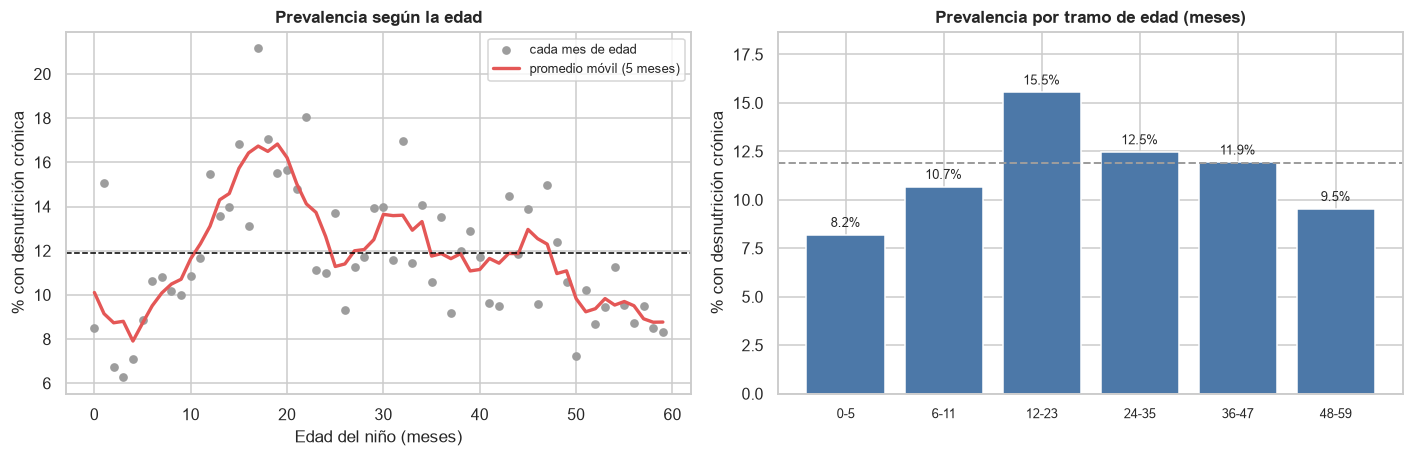

In [21]:
# Evolución con la edad
por_mes = dr.groupby("edad_meses")["desnutricion_cronica"].mean().mul(100)
suave = por_mes.rolling(5, center=True, min_periods=1).mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].scatter(por_mes.index, por_mes.values, s=22, color=GRIS, label="cada mes de edad")
axes[0].plot(suave.index, suave.values, color=ROJO, lw=2.2, label="promedio móvil (5 meses)")
axes[0].axhline(PREV, color="black", ls="--", lw=1)
axes[0].set_xlabel("Edad del niño (meses)")
axes[0].set_ylabel("% con desnutrición crónica")
axes[0].set_title("Prevalencia según la edad")
axes[0].legend(fontsize=8.5)

prevalencia(axes[1], grupo_edad_dr, "Prevalencia por tramo de edad (meses)", color=AZUL)
plt.tight_layout()
plt.show()

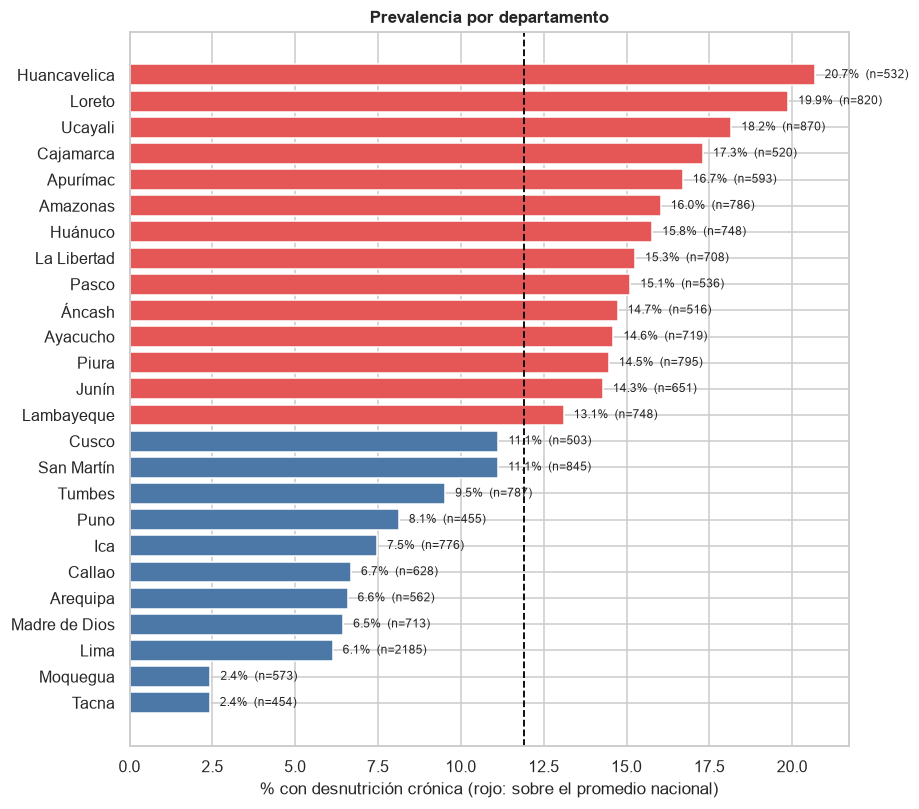

In [22]:
# Por departamento (código ENDES)
DEPTOS = {1: "Amazonas", 2: "Áncash", 3: "Apurímac", 4: "Arequipa", 5: "Ayacucho", 6: "Cajamarca", 7: "Callao", 8: "Cusco",
          9: "Huancavelica", 10: "Huánuco", 11: "Ica", 12: "Junín", 13: "La Libertad", 14: "Lambayeque", 15: "Lima",
          16: "Loreto", 17: "Madre de Dios", 18: "Moquegua", 19: "Pasco", 20: "Piura", 21: "Puno", 22: "San Martín",
          23: "Tacna", 24: "Tumbes", 25: "Ucayali"}
pd_ = dr.groupby("departamento")["desnutricion_cronica"].agg(["mean", "size"])
pd_["mean"] *= 100
pd_.index = pd_.index.map(DEPTOS)
pd_ = pd_.sort_values("mean")

fig, ax = plt.subplots(figsize=(8.5, 7.5))
colores = [ROJO if m > PREV else AZUL for m in pd_["mean"]]
ax.barh(pd_.index, pd_["mean"], color=colores)
for i, (m, n) in enumerate(zip(pd_["mean"], pd_["size"])):
    ax.text(m + 0.3, i, f"{m:.1f}%  (n={n})", va="center", fontsize=8)
ax.axvline(PREV, color="black", ls="--", lw=1.2)
ax.set_xlabel("% con desnutrición crónica (rojo: sobre el promedio nacional)")
ax.set_title("Prevalencia por departamento")
plt.tight_layout()
plt.show()

**Lectura:** la desnutrición crónica se concentra donde hay más pobreza y menos educación: 21.9 % en el quintil más pobre frente a 3.9 % en el más rico; 21.0 % en zona rural frente a 8.2 % en urbana; 32.5 % si la madre no tiene educación frente a 6.3 % si tiene superior; Sierra (16.3 %) y Selva (14.1 %) frente a Lima (5.7 %); sobre los 2 500 m sube a ≈ 17 % (frente a 10 % bajo los 500 m). Los varones tienen algo más (12.9 % frente a 10.8 %). Por departamento va de 2.4 % (Moquegua, Tacna) a 20.7 % (Huancavelica) y 19.9 % (Loreto). **La edad no se comporta como una recta:** sube hasta un máximo de 15.5 % entre los 12 y 23 meses (coincide con el paso a la alimentación complementaria) y luego baja a 9.5 % a los 48-59 meses. Es una relación **no lineal**, que una regresión lineal no capta y los árboles sí.

## 6. Distribución de las variables
Histogramas de las numéricas y barras de las categóricas, **en crudo**: los picos aislados a la derecha (9996, 9999…) son códigos especiales.

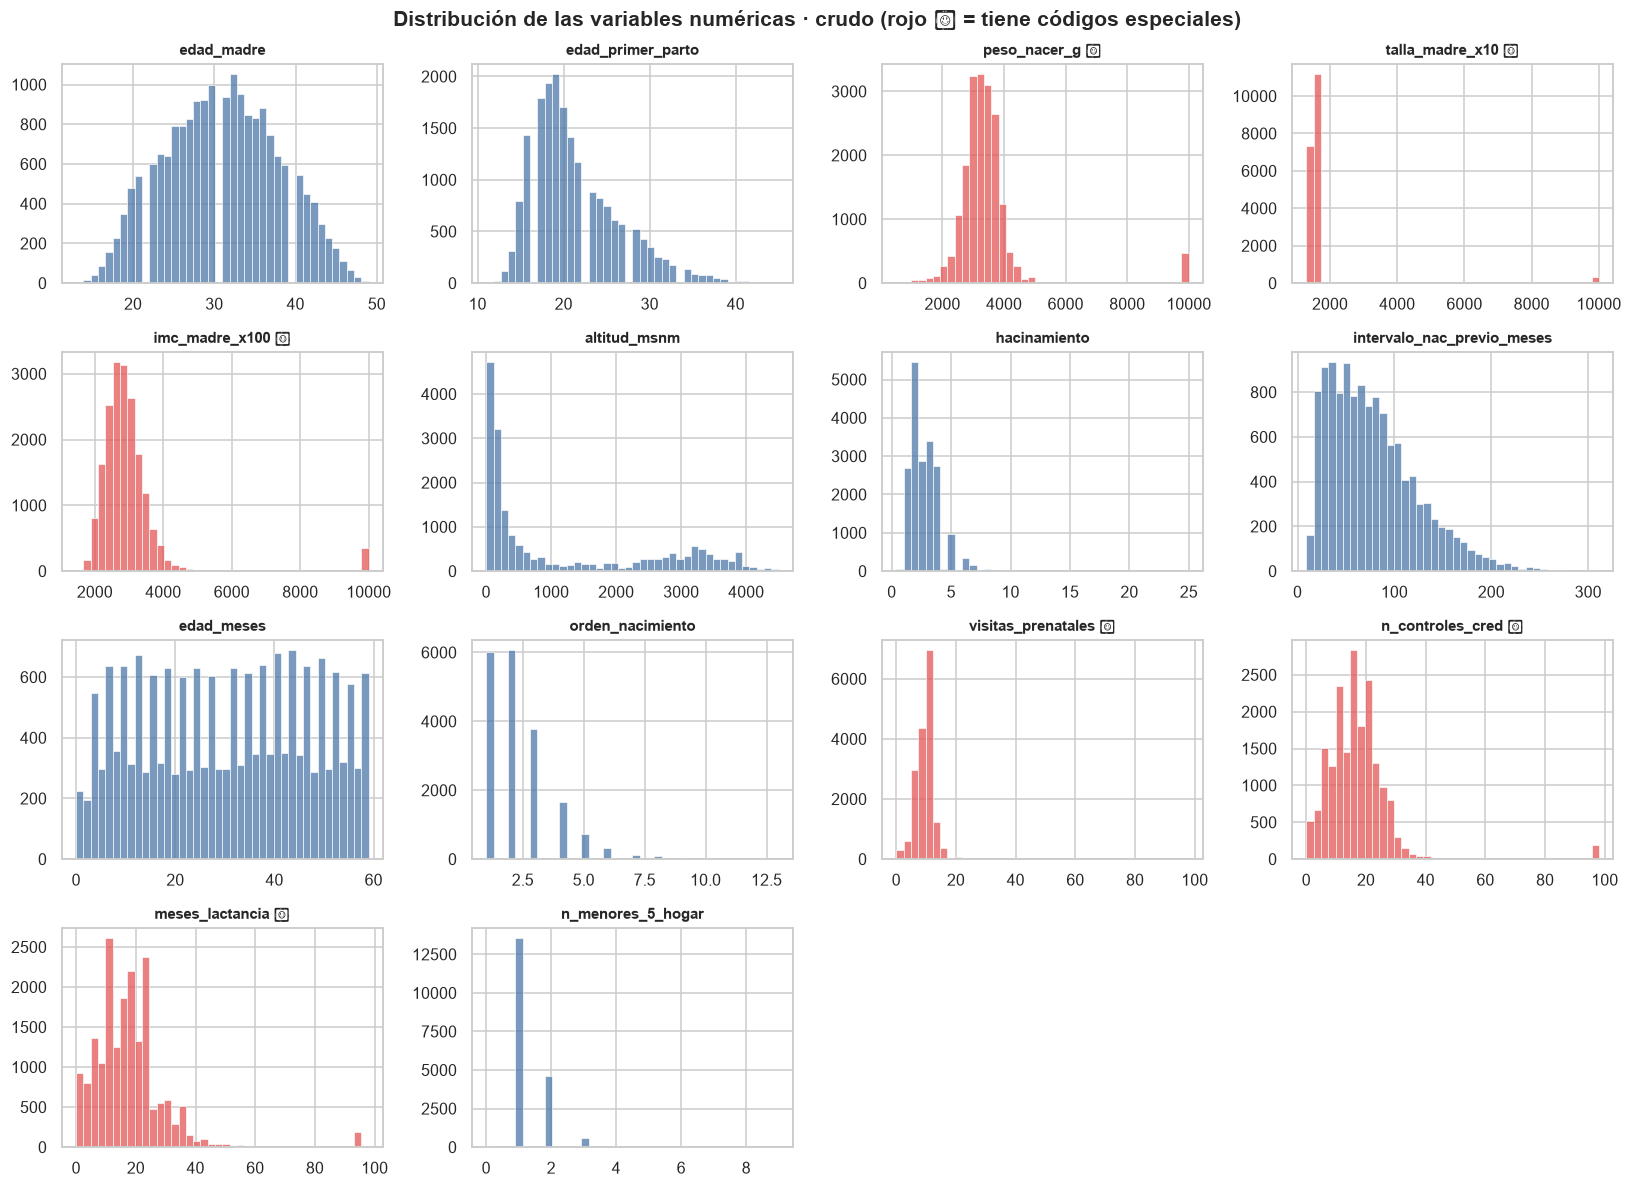

In [23]:
vars_hist = CONTINUAS + DISCRETAS
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
for ax, var in zip(axes.ravel(), vars_hist):
    sns.histplot(df[var].dropna(), bins=40, color=ROJO if var in CODIGOS else AZUL, ax=ax)
    ax.set_title(var + (" ⚠" if var in CODIGOS else ""), fontsize=9.5)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axes.ravel()[len(vars_hist):]:
    ax.axis("off")
fig.suptitle("Distribución de las variables numéricas · crudo (rojo ⚠ = tiene códigos especiales)", fontweight="bold")
plt.tight_layout()
plt.show()

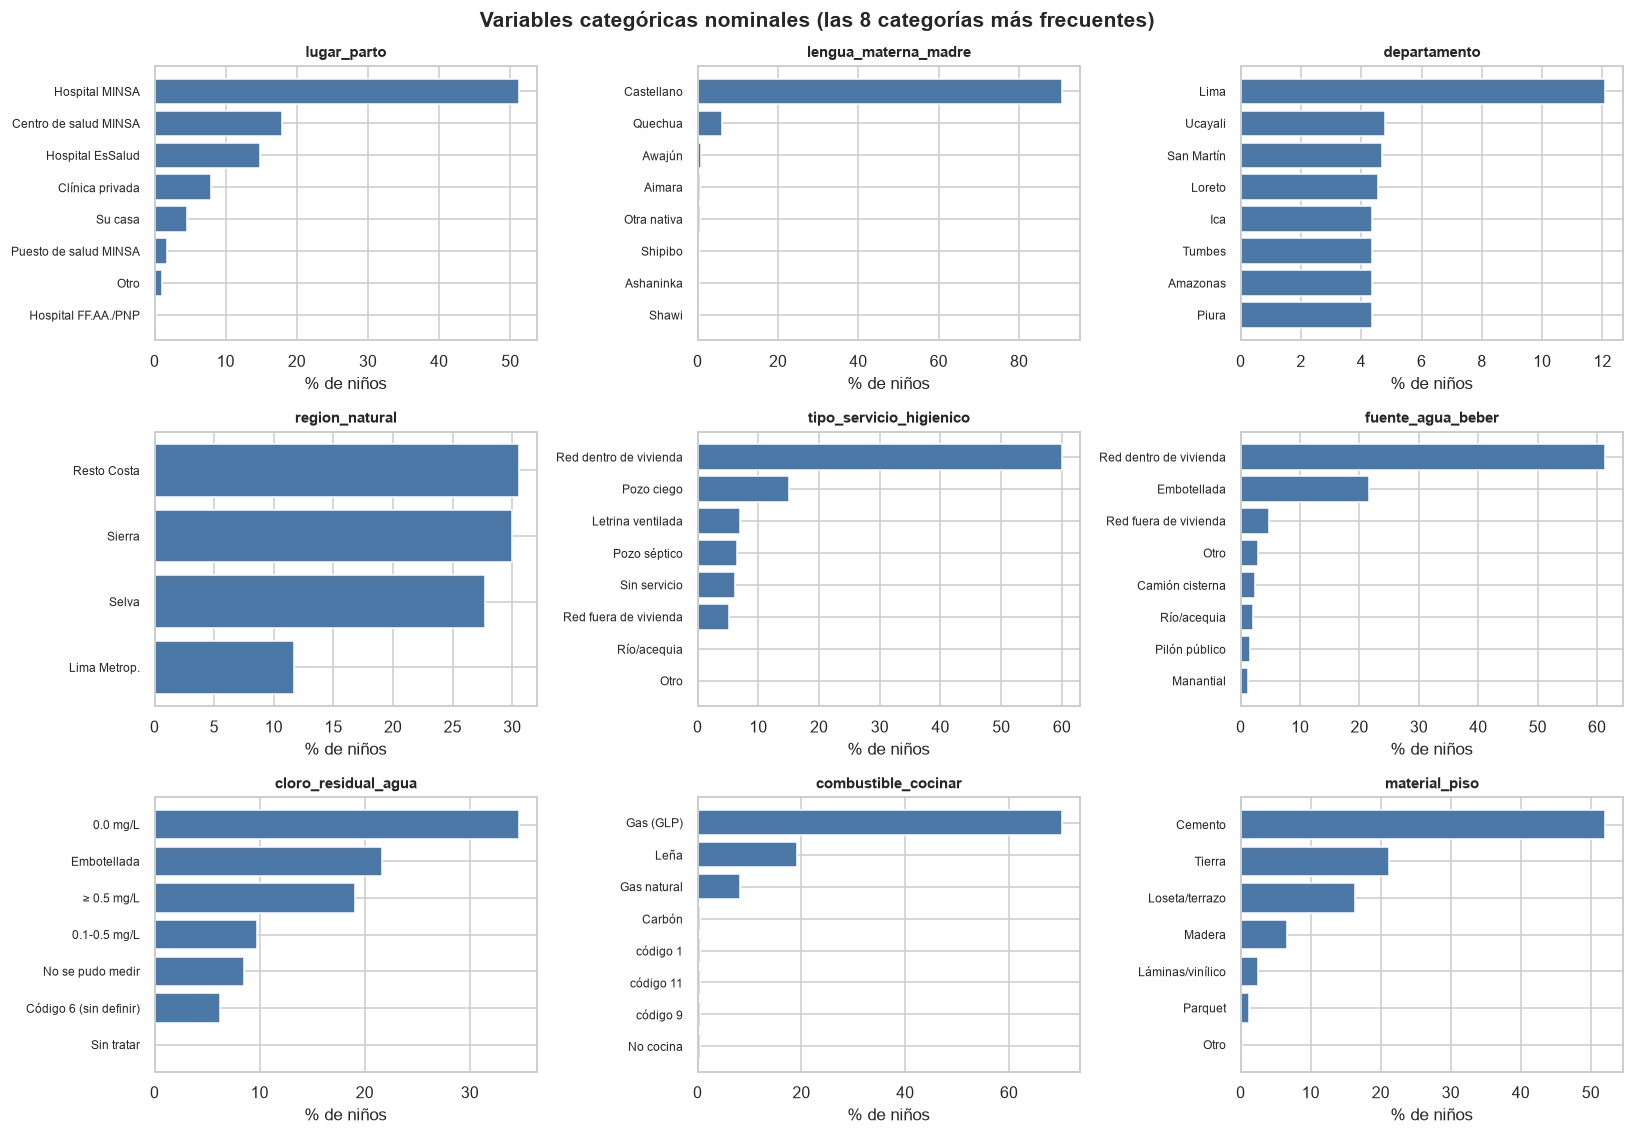

In [24]:
# Variables categóricas nominales: % de niños por categoría (nombres tomados del diccionario INEI)
NOMBRES = {
    "lugar_parto": {11: "Su casa", 12: "Otra casa", 21: "Hospital MINSA", 22: "Hospital EsSalud", 23: "Hospital FF.AA./PNP",
                    24: "Centro de salud MINSA", 25: "Puesto de salud MINSA", 26: "Posta EsSalud", 27: "Hospital municipal",
                    31: "Clínica privada", 32: "Consultorio privado", 41: "ONG", 42: "Iglesia", 96: "Otro"},
    "lengua_materna_madre": {1: "Quechua", 2: "Aimara", 3: "Ashaninka", 4: "Awajún", 5: "Shipibo", 6: "Shawi", 7: "Matsigenka",
                             8: "Achuar", 9: "Otra nativa", 10: "Castellano", 11: "Portugués", 12: "Otra extranjera", 13: "Sordomudo"},
    "departamento": DEPTOS,
    "region_natural": ETQ["region_natural"],
    "tipo_servicio_higienico": {11: "Red dentro de vivienda", 12: "Red fuera de vivienda", 21: "Letrina ventilada", 22: "Pozo séptico",
                                23: "Pozo ciego", 24: "Letrina colgante", 31: "Río/acequia", 32: "Sin servicio", 96: "Otro"},
    "fuente_agua_beber": {11: "Red dentro de vivienda", 12: "Red fuera de vivienda", 13: "Pilón público", 21: "Pozo en vivienda",
                          22: "Pozo público", 41: "Manantial", 43: "Río/acequia", 51: "Lluvia", 61: "Camión cisterna",
                          71: "Embotellada", 96: "Otro"},
    "cloro_residual_agua": {1: "≥ 0.5 mg/L", 2: "0.1-0.5 mg/L", 3: "0.0 mg/L", 4: "Sin tratar", 5: "Embotellada",
                            6: "Código 6 (sin definir)", 9: "No se pudo medir"},
    "combustible_cocinar": {2: "Gas (GLP)", 3: "Gas natural", 7: "Carbón", 8: "Leña", 95: "No cocina"},
    "material_piso": {11: "Tierra", 21: "Madera", 31: "Parquet", 32: "Láminas/vinílico", 33: "Loseta/terrazo", 34: "Cemento", 96: "Otro"},
}
fig, axes = plt.subplots(3, 3, figsize=(15, 10.5))
for ax, var in zip(axes.ravel(), CATEG):
    p = df[var].value_counts(normalize=True).mul(100).sort_values(ascending=True).tail(8)
    etiquetas = [NOMBRES.get(var, {}).get(int(c), f"código {int(c)}") for c in p.index]
    ax.barh(etiquetas, p.values, color=AZUL)
    ax.set_title(var, fontsize=10)
    ax.tick_params(axis="y", labelsize=8)
    ax.set_xlabel("% de niños")
for ax in axes.ravel()[len(CATEG):]:
    ax.axis("off")
plt.suptitle("Variables categóricas nominales (las 8 categorías más frecuentes)", fontweight="bold")
plt.tight_layout()
plt.show()

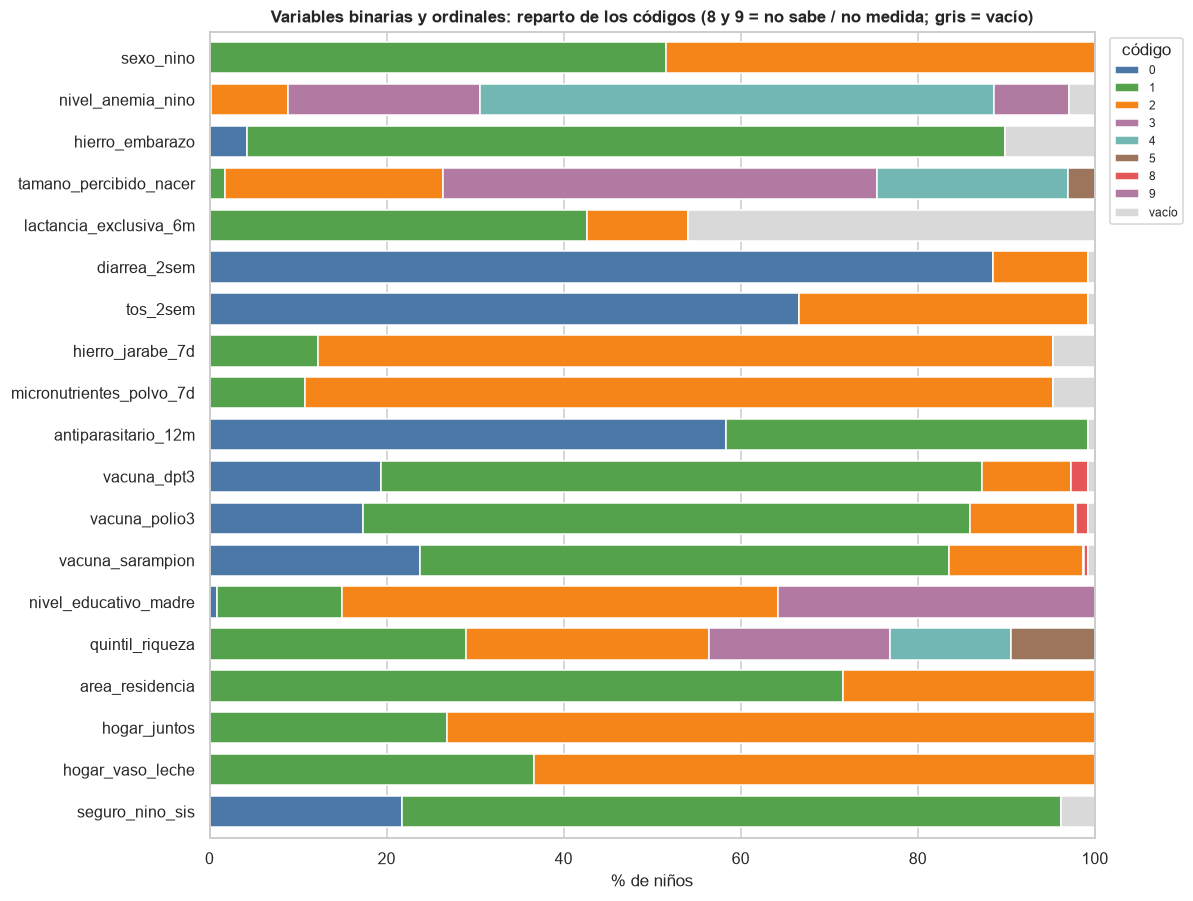

In [25]:
# Variables binarias y ordinales: barra apilada al 100 % por código
cols_bo = tipos.loc[tipos.naturaleza.isin(["binaria", "ordinal"]), "variable"].tolist()
tabla_bo = pd.DataFrame({v: df[v].value_counts(normalize=True, dropna=False).mul(100) for v in cols_bo}).T
tabla_bo.columns = ["vacío" if pd.isna(c) else str(int(c)) for c in tabla_bo.columns]
orden_codigos = [c for c in ["0", "1", "2", "3", "4", "5", "8", "9", "vacío"] if c in tabla_bo.columns]
paleta = {"0": "#4C78A8", "1": "#54A24B", "2": "#F58518", "3": "#B279A2", "4": "#72B7B2", "5": "#9D755D",
          "8": "#E45756", "9": "#B07AA1", "vacío": "#D9D9D9"}
tabla_bo = tabla_bo[orden_codigos].fillna(0)

fig, ax = plt.subplots(figsize=(11, 0.36 * len(cols_bo) + 1.5))
tabla_bo.plot.barh(stacked=True, ax=ax, color=[paleta[c] for c in orden_codigos], width=0.75)
ax.invert_yaxis()
ax.set_xlabel("% de niños")
ax.set_title("Variables binarias y ordinales: reparto de los códigos (8 y 9 = no sabe / no medida; gris = vacío)")
ax.legend(title="código", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Lectura:** los histogramas muestran dos tipos de problema: picos aislados a la derecha (códigos 9996-9999 en peso, talla e IMC; 98 en controles) y colas largas reales (hacinamiento, orden de nacimiento, intervalo entre hijos). En las categóricas: el 91 % de las madres tiene el castellano como lengua materna; el 60 % tiene baño con red pública dentro de la vivienda; el gas cocina en el 70 % de los hogares y la leña en el 19 %; el 51 % tiene piso de cemento pero el 21 % de tierra. En el gráfico de barras al 100 %: más de 8 de cada 10 niños no tomó hierro en jarabe la última semana; solo el 27 % de los hogares recibe Juntos y el 37 % Vaso de Leche; cerca del 75 % de los niños tiene SIS. (Atención: el significado de cada código depende de la variable; ver el diccionario.)

## 7. Relación de las variables con el objetivo
Gráficos de la Semana 05 (EDA): dispersión de cada predictor contra el `haz` y cajas por categoría. Se mantienen los códigos especiales para ver **qué le llega realmente al modelo**.

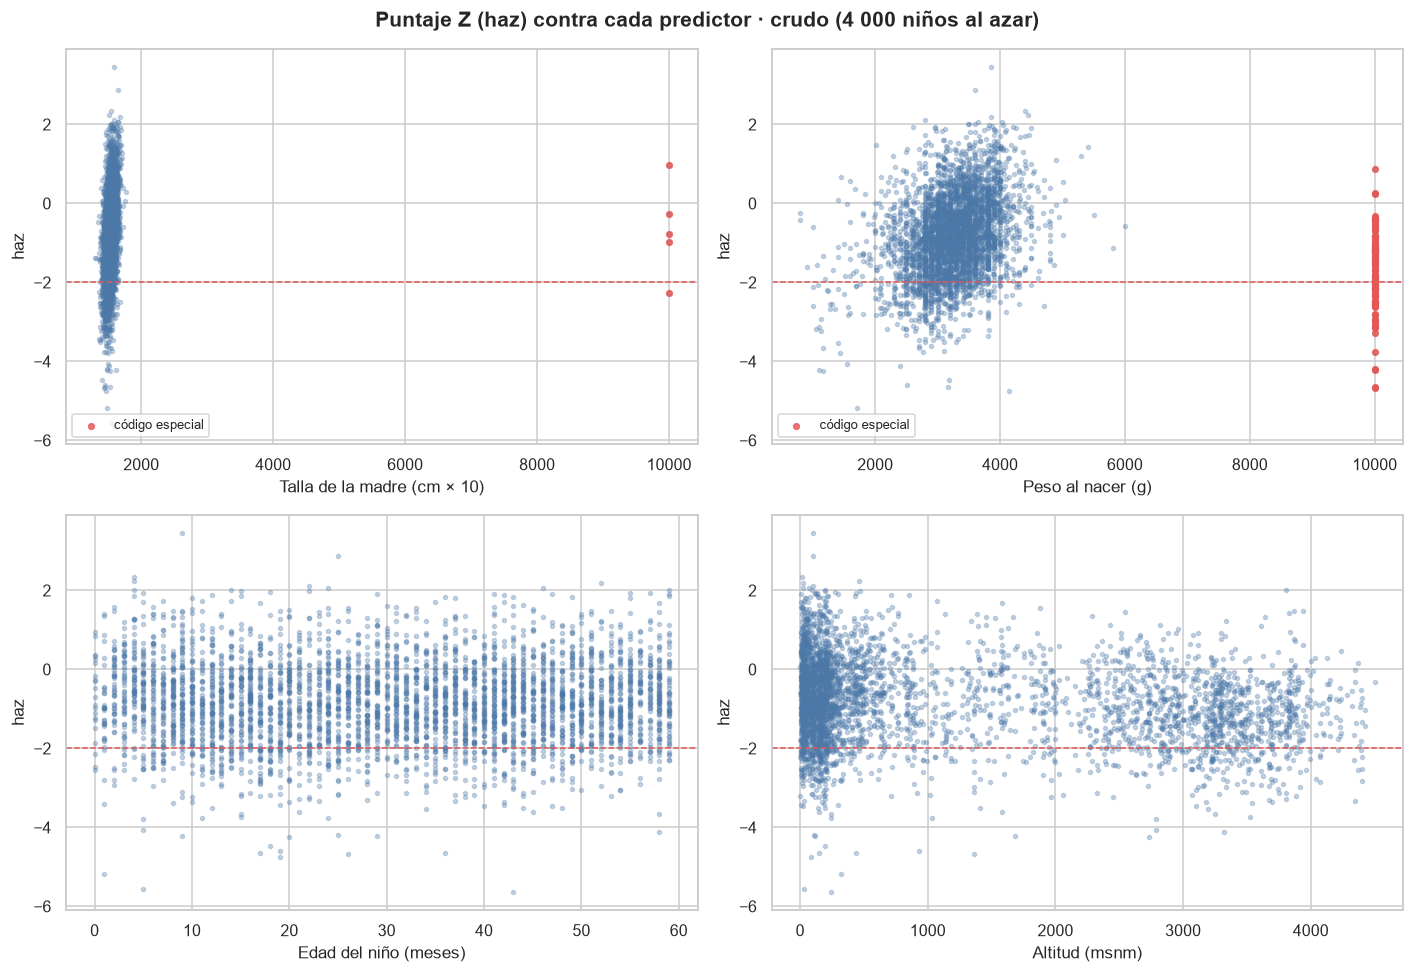

In [26]:
muestra = dr.sample(4000, random_state=42)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
pares = [("talla_madre_x10", "Talla de la madre (cm × 10)"), ("peso_nacer_g", "Peso al nacer (g)"),
         ("edad_meses", "Edad del niño (meses)"), ("altitud_msnm", "Altitud (msnm)")]
for ax, (var, nombre) in zip(axes.ravel(), pares):
    ax.scatter(muestra[var], muestra["haz"], s=7, alpha=0.3, color=AZUL)
    if var in CODIGOS:
        malos = muestra[muestra[var].isin(CODIGOS[var])]
        ax.scatter(malos[var], malos["haz"], s=14, alpha=0.8, color=ROJO, label="código especial")
        ax.legend(fontsize=8.5, loc="lower left")
    ax.axhline(-2, color=ROJO, ls="--", lw=1)
    ax.set_xlabel(nombre)
    ax.set_ylabel("haz")
fig.suptitle("Puntaje Z (haz) contra cada predictor · crudo (4 000 niños al azar)", fontweight="bold")
plt.tight_layout()
plt.show()

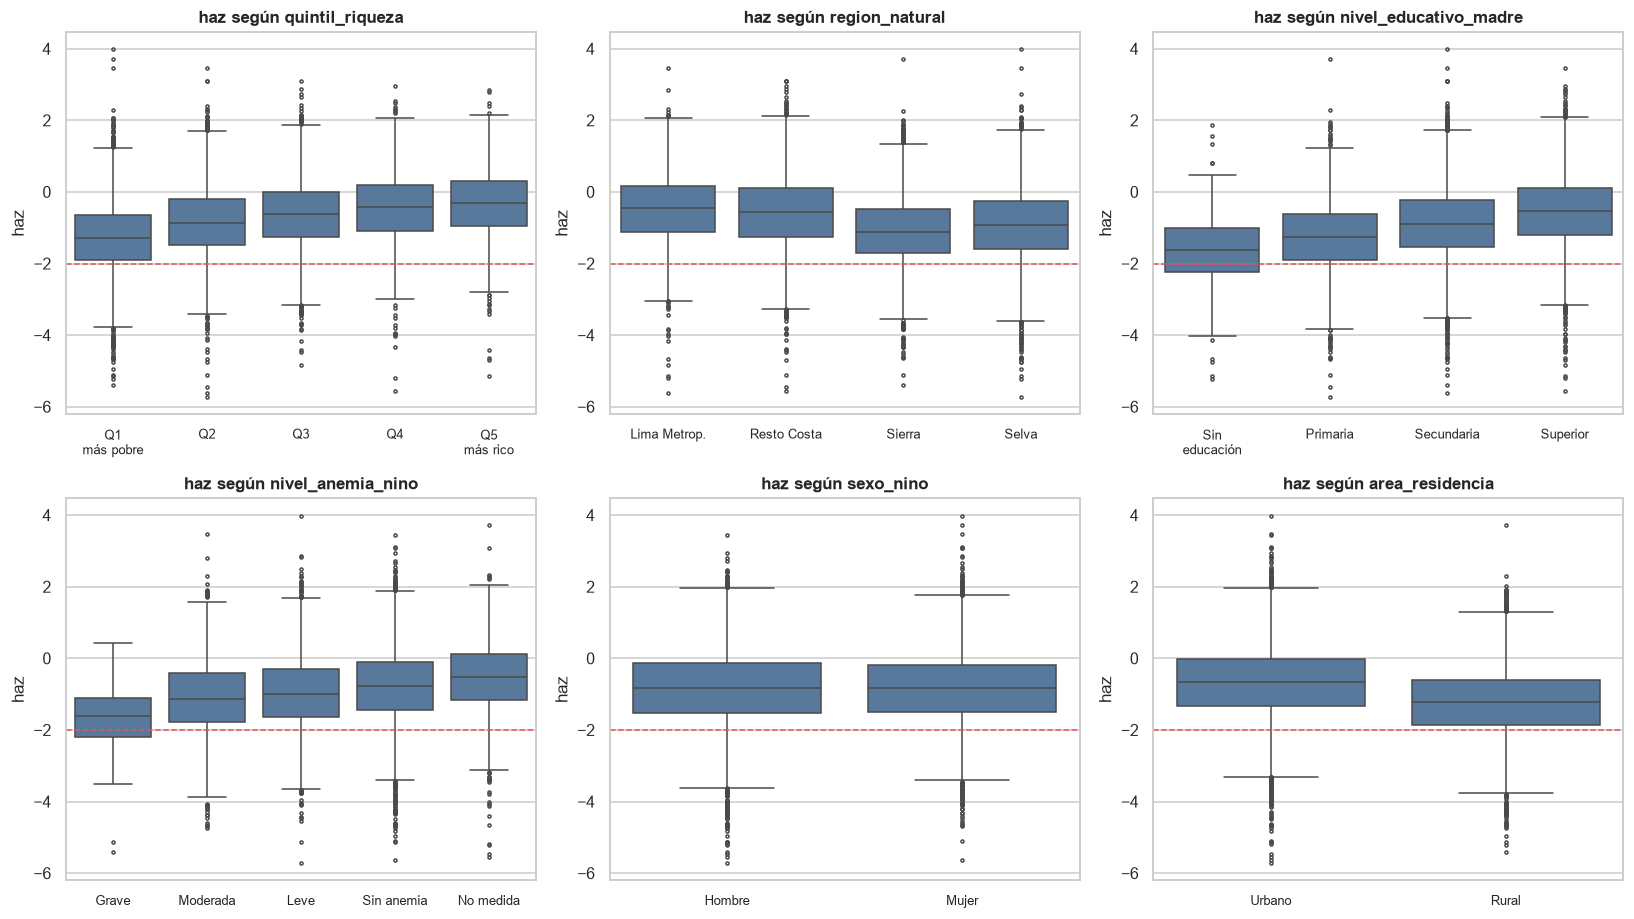

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, var in zip(axes.ravel(), ["quintil_riqueza", "region_natural", "nivel_educativo_madre", "nivel_anemia_nino", "sexo_nino", "area_residencia"]):
    ord_ = sorted(dr[var].dropna().unique())
    sns.boxplot(data=dr, x=var, y="haz", order=ord_, ax=ax, color=AZUL, fliersize=2)
    ax.set_xticklabels([ETQ.get(var, {}).get(int(c), str(int(c))) for c in ord_], fontsize=8.5)
    ax.axhline(-2, color=ROJO, ls="--", lw=1)
    ax.set_xlabel("")
    ax.set_title(f"haz según {var}")
plt.tight_layout()
plt.show()

Los mismos dos gráficos **sin los códigos especiales** (en una copia), para ver la relación real y su recta de tendencia.

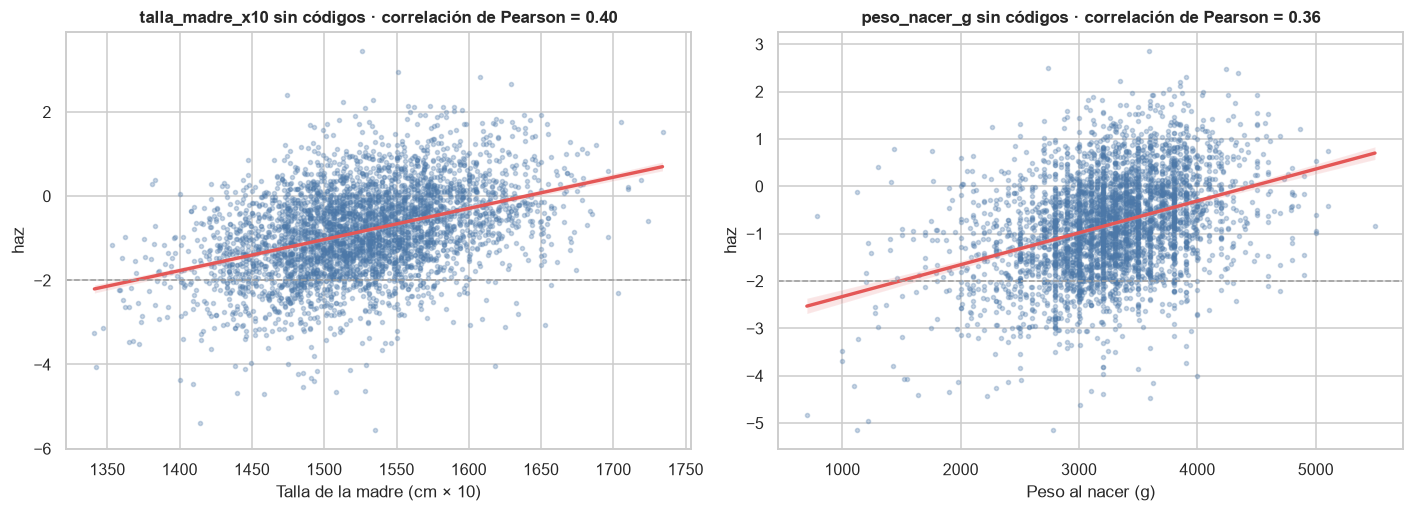

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (var, nombre) in zip(axes, [("talla_madre_x10", "Talla de la madre (cm × 10)"), ("peso_nacer_g", "Peso al nacer (g)")]):
    limpio = pd.DataFrame({"x": sin_codigos(dr[var]), "haz": dr["haz"]}).dropna().sample(4000, random_state=42)
    sns.regplot(data=limpio, x="x", y="haz", ax=ax, scatter_kws={"s": 7, "alpha": 0.3, "color": AZUL}, line_kws={"color": ROJO, "lw": 2.2})
    r = limpio["x"].corr(limpio["haz"])
    ax.axhline(-2, color=GRIS, ls="--", lw=1)
    ax.set_xlabel(nombre)
    ax.set_ylabel("haz")
    ax.set_title(f"{var} sin códigos · correlación de Pearson = {r:.2f}")
plt.tight_layout()
plt.show()

**Lectura:** en crudo, la talla de la madre (9999) y el peso al nacer (9996-9998) muestran puntos rojos aislados lejos de la nube real, que queda apretada en un extremo del gráfico. Al quitar esos códigos (figura siguiente) aparece la relación: madres más altas y bebés más pesados tienen niños con mayor `haz`. La edad y la altitud no forman una recta (la altitud separa dos nubes: sobre y bajo ≈ 2 500 m). Las cajas confirman las tablas: el `haz` sube con la riqueza y la educación de la madre, baja en Sierra, Selva y zonas rurales, y es más bajo con anemia grave o moderada; el sexo casi no separa las cajas.

## 8. Correlación
La Semana 03 usa la correlación (−1 a 1) para decidir qué variables aportan. Se comparan **Pearson** (relación lineal, sensible a los códigos especiales) y **Spearman** (por rangos, más robusta). Las categóricas nominales no se incluyen: su código no es una escala.

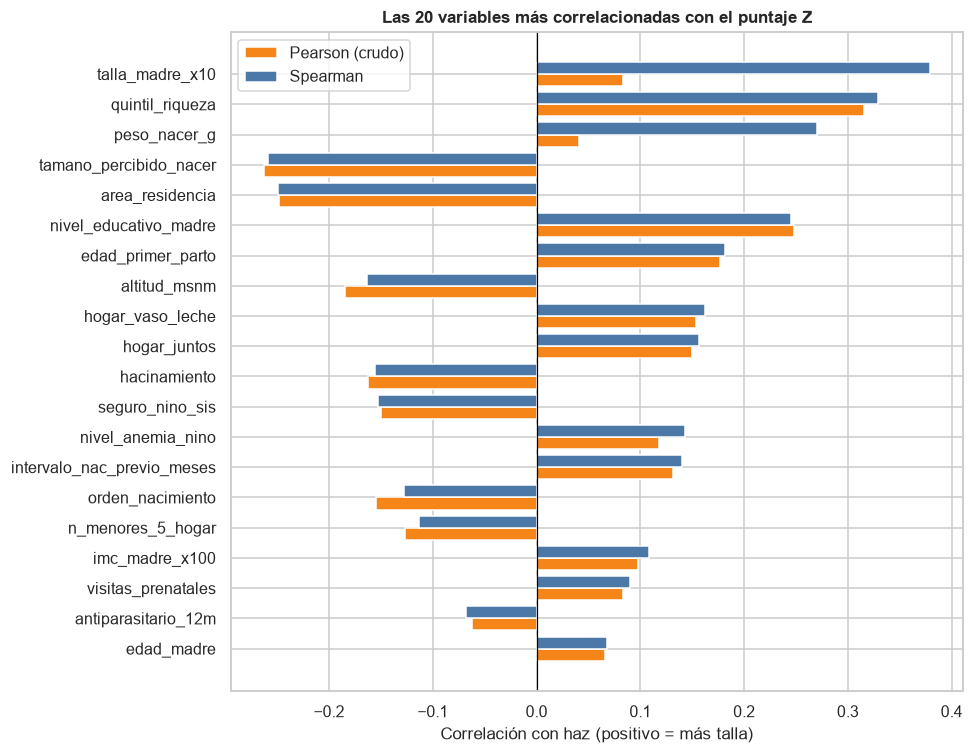

,Pearson,Spearman
talla_madre_x10,0.083,0.379
quintil_riqueza,0.315,0.329
peso_nacer_g,0.041,0.270
tamano_percibido_nacer,-0.263,-0.259
area_residencia,-0.248,-0.249
nivel_educativo_madre,0.248,0.246
edad_primer_parto,0.176,0.182
altitud_msnm,-0.185,-0.163
hogar_vaso_leche,0.154,0.162
hogar_juntos,0.150,0.157


In [29]:
num_ord = [c for c in NUM]
pear = dr[num_ord].corrwith(dr["haz"], method="pearson")
spea = dr[num_ord].corrwith(dr["haz"], method="spearman")
cor = pd.DataFrame({"Pearson": pear, "Spearman": spea})
cor = cor.reindex(cor["Spearman"].abs().sort_values(ascending=False).index)

top = cor.head(20)[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
y_ = np.arange(len(top))
ax.barh(y_ - 0.2, top["Pearson"], height=0.4, color=NARANJA, label="Pearson (crudo)")
ax.barh(y_ + 0.2, top["Spearman"], height=0.4, color=AZUL, label="Spearman")
ax.set_yticks(y_)
ax.set_yticklabels(top.index)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Correlación con haz (positivo = más talla)")
ax.set_title("Las 20 variables más correlacionadas con el puntaje Z")
ax.legend()
plt.tight_layout()
plt.show()
cor.round(3).head(12)

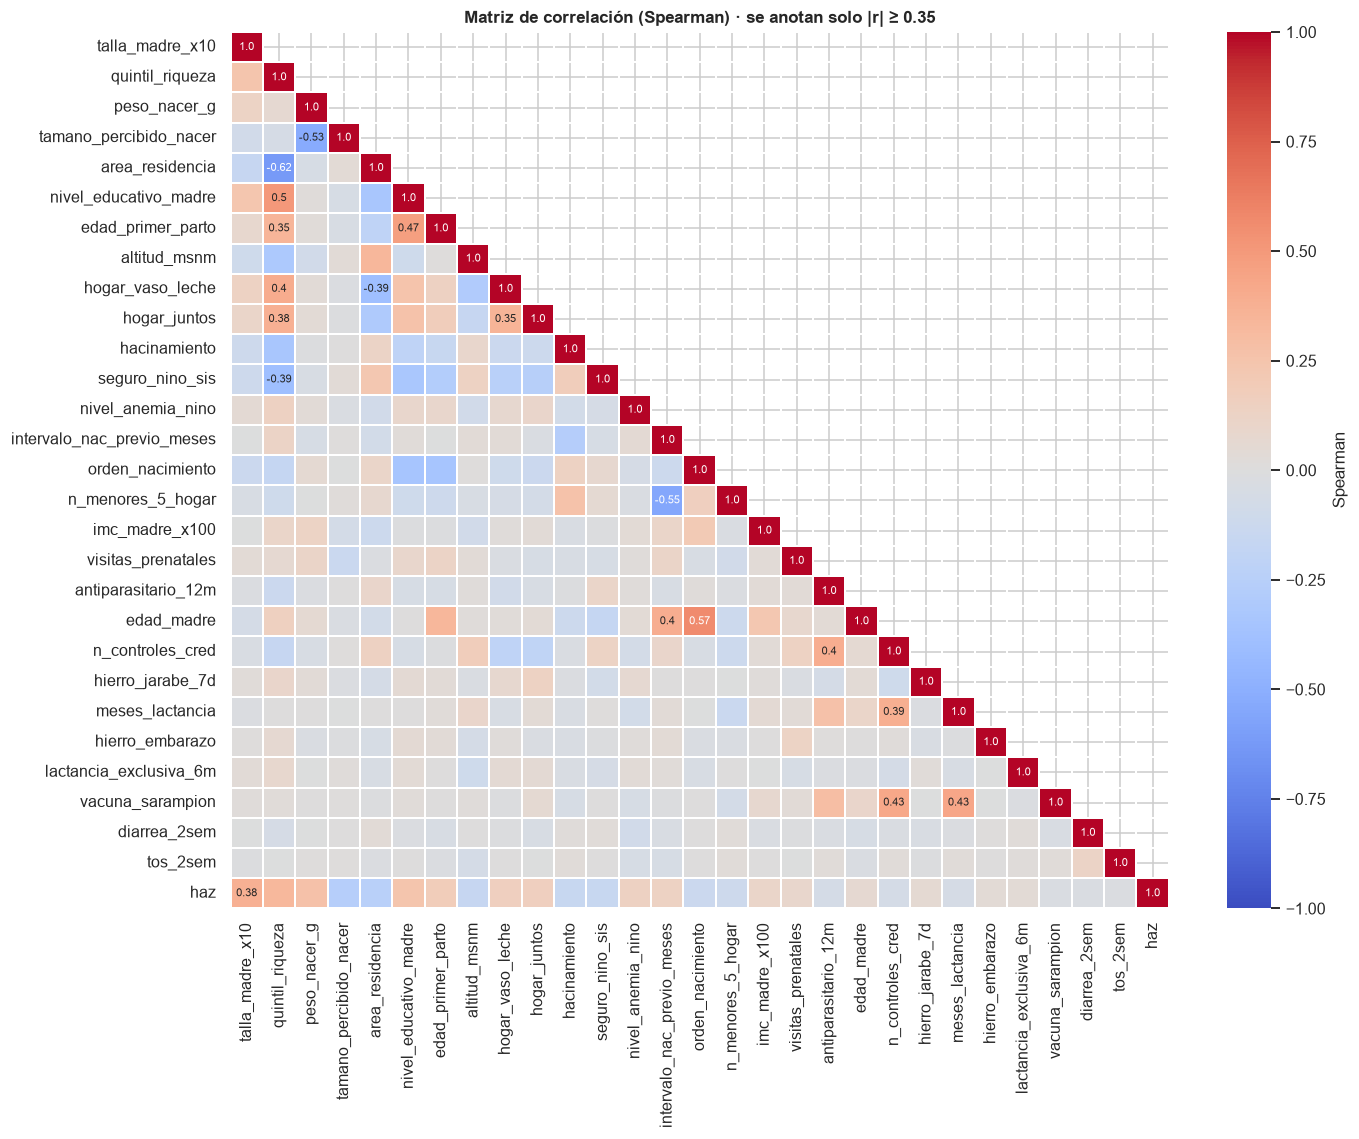

Pares de predictoras muy correlacionadas (|r| ≥ 0.6):


,variable A,variable B,r
0,area_residencia,quintil_riqueza,-0.62


In [30]:
# Mapa de calor entre las numéricas (Spearman). Se anota solo |r| >= 0.35 para que se lea
vars_mapa = cor.index[:28].tolist() + ["haz"]
c2 = dr[vars_mapa].corr(method="spearman")
mascara = np.triu(np.ones_like(c2, dtype=bool), k=1)
anot = np.where(c2.abs() >= 0.35, c2.round(2).astype(str), "")

fig, ax = plt.subplots(figsize=(13, 10.5))
sns.heatmap(c2, mask=mascara, cmap="coolwarm", vmin=-1, vmax=1, center=0, annot=anot, fmt="", annot_kws={"size": 7},
            linewidths=0.3, cbar_kws={"label": "Spearman"}, ax=ax)
ax.set_title("Matriz de correlación (Spearman) · se anotan solo |r| ≥ 0.35")
plt.tight_layout()
plt.show()

pares = (c2.where(~mascara).stack().rename("r").reset_index().rename(columns={"level_0": "variable A", "level_1": "variable B"}))
pares = pares[(pares["variable A"] != pares["variable B"]) & (pares["r"].abs() >= 0.6)].sort_values("r", key=abs, ascending=False)
print("Pares de predictoras muy correlacionadas (|r| ≥ 0.6):")
pares.round(2).reset_index(drop=True)

**Lectura:** la talla de la madre es la variable más ligada al `haz` (Spearman +0.38), seguida de la riqueza (+0.33), el peso al nacer (+0.27), el tamaño percibido al nacer (−0.26), el área rural (−0.25) y la educación de la madre (+0.25). **Pearson y Spearman discrepan mucho donde hay códigos especiales:** talla materna 0.08 frente a 0.38, peso al nacer 0.04 frente a 0.27; los códigos 9999 y 9998 arruinan la correlación lineal. Los signos de `hogar_juntos`, `hogar_vaso_leche` y `seguro_nino_sis` parecen al revés porque 1 = sí: los programas llegan a los hogares más pobres, así que "recibir" se asocia con menor `haz` (refleja pobreza, no efecto del programa). Entre predictoras, el único par con |r| ≥ 0.6 es área rural-quintil de riqueza (−0.62); otros pares moderados: edad de la madre y orden de nacimiento (0.57), intervalo entre hijos y menores de 5 en el hogar (−0.55), educación y riqueza (0.50). Es redundancia moderada, sin problema para los árboles; en regresión lineal conviene vigilarla.

## 9. Preparación para modelar: codificación, escalado y división
Tres decisiones de la Semana 04 que condicionan todo lo que sigue. Aquí solo se **diagnostican** (en copias); se aplican en el notebook 03.

### 9.1 Codificación de las variables categóricas
- **Ordinales** (`quintil_riqueza`, `nivel_educativo_madre`…): se asigna el orden real a mano, nunca `LabelEncoder` (daría orden alfabético).
- **Binarias:** 0/1.
- **Nominales** (departamento, lengua, lugar de parto…): *One-Hot* (cada código es una columna) o `category` en XGBoost. Un código grande no significa "más".

In [31]:
plan = tipos.copy()
plan["tratamiento previsto"] = plan.naturaleza.map({
    "continua": "numérica: códigos especiales → NaN; escalar solo para regresión lineal",
    "discreta": "numérica: códigos especiales → NaN",
    "ordinal": "mapa manual que respete el orden (sin LabelEncoder)",
    "binaria": "recodificar a 0/1 (1-3 = sí en vacunas; 8 → NaN)",
    "nominal": "One-Hot (o category + enable_categorical en XGBoost)",
})
plan.groupby(["naturaleza", "tratamiento previsto"]).variable.apply(lambda s: ", ".join(s)).to_frame("variables")

,,variables
naturaleza,tratamiento previsto,
binaria,recodificar a 0/1 (1-3 = sí en vacunas; 8 → NaN),"sexo_nino, hierro_embarazo, lactancia_exclusiva_6m, hierro_jarabe_7d, micron..."
continua,numérica: códigos especiales → NaN; escalar solo para regresión lineal,"intervalo_nac_previo_meses, peso_nacer_g, edad_madre, edad_primer_parto, tal..."
discreta,numérica: códigos especiales → NaN,"edad_meses, orden_nacimiento, visitas_prenatales, meses_lactancia, n_control..."
nominal,One-Hot (o category + enable_categorical en XGBoost),"lugar_parto, lengua_materna_madre, departamento, region_natural, tipo_servic..."
ordinal,mapa manual que respete el orden (sin LabelEncoder),"nivel_anemia_nino, tamano_percibido_nacer, diarrea_2sem, tos_2sem, nivel_edu..."


### 9.2 Escalado: Min-Max y Z-score
Las variables tienen escalas muy distintas (años, gramos, metros de altitud). Regresión lineal y modelos basados en distancias lo necesitan; los árboles (Random Forest, XGBoost) no. Se compara en una **copia**, con cuatro variables.

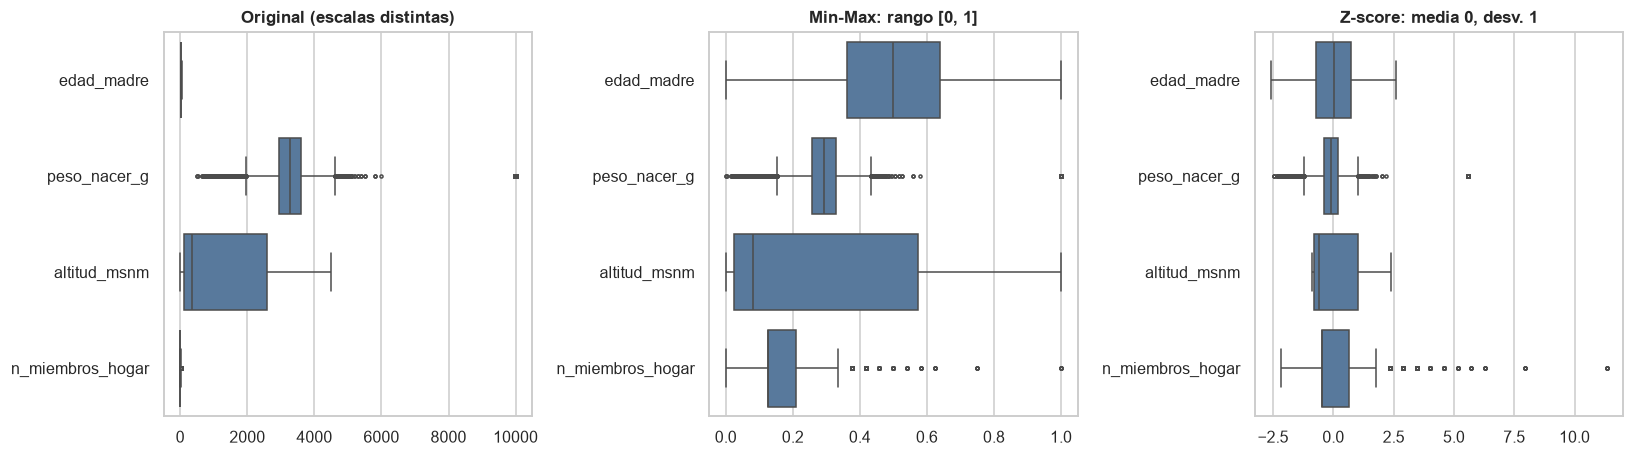

edad_madre  peso_nacer_g  altitud_msnm  n_miembros_hogar
Min-Max min         0.00          0.00          0.00              0.00
        max         1.00          1.00          1.00              1.00
Z-score mean        0.00         -0.00         -0.00             -0.00
        std         1.00          1.00          1.00              1.00
        min        -2.57         -2.46         -0.87             -2.15
        max         2.59          5.57          2.40             11.33

In [32]:
vars_esc = ["edad_madre", "peso_nacer_g", "altitud_msnm", "n_miembros_hogar"]
copia = df[vars_esc].dropna()
minmax = pd.DataFrame(MinMaxScaler().fit_transform(copia), columns=vars_esc)
zscore = pd.DataFrame(StandardScaler().fit_transform(copia), columns=vars_esc)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (datos, titulo) in zip(axes, [(copia, "Original (escalas distintas)"), (minmax, "Min-Max: rango [0, 1]"), (zscore, "Z-score: media 0, desv. 1")]):
    sns.boxplot(data=datos, ax=ax, color=AZUL, fliersize=2, orient="h")
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

pd.concat({"Min-Max": minmax.describe().loc[["min", "max"]], "Z-score": zscore.describe().loc[["mean", "std", "min", "max"]]}).round(2)

**Lectura:** las cuatro variables parten de escalas muy distintas (altitud hasta 4 500, edad de la madre hasta 49, tamaño del hogar hasta 25). Min-Max las lleva a [0, 1] y Z-score a media 0 y desviación 1 (con valores negativos). Se nota el efecto de los **atípicos**: el peso al nacer llega a z = 5.6 por el código 9998 y el tamaño del hogar a z = 11.3; con Min-Max esos extremos aplastan al resto. Por eso el escalado va **después** de pasar los códigos a `NaN`, y solo hace falta para la regresión lineal (los árboles no lo necesitan).

### 9.3 División train/test y fuga de datos
La guía exige separar entrenamiento y prueba **antes** de calcular medias o mínimos. Hay un segundo riesgo, propio de ENDES: los niños de un mismo **conglomerado** (y los hermanos de una misma madre) se parecen entre sí. Si unos quedan en train y otros en test, el modelo podría "reconocer" el conglomerado y el rendimiento saldría inflado. Se mide cuánto cambia con el mismo modelo y dos formas de dividir.

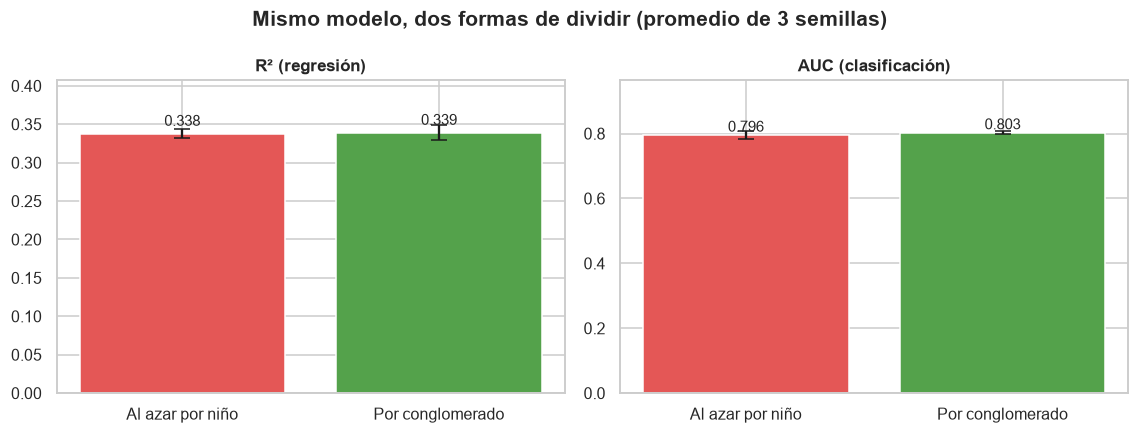

R² (regresión)        AUC (clasificación)       
                           mean    std                mean    std
división                                                         
Al azar por niño          0.338  0.006               0.796  0.012
Por conglomerado          0.339  0.010               0.803  0.004

In [33]:
X_all = dr[FEATURES]
y_reg = dr["haz"]
y_cls = dr["desnutricion_cronica"]
grupos = dr["conglomerado"]

resultados = []
for semilla in [1, 2, 3]:
    for nombre, divisor in [("Al azar por niño", ShuffleSplit(n_splits=1, test_size=0.2, random_state=semilla)),
                            ("Por conglomerado", GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=semilla))]:
        tr_, te_ = next(divisor.split(X_all, y_reg, groups=grupos))
        reg = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=42).fit(X_all.iloc[tr_], y_reg.iloc[tr_])
        cls = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=42).fit(X_all.iloc[tr_], y_cls.iloc[tr_])
        resultados.append({"división": nombre, "semilla": semilla,
                           "R² (regresión)": r2_score(y_reg.iloc[te_], reg.predict(X_all.iloc[te_])),
                           "AUC (clasificación)": roc_auc_score(y_cls.iloc[te_], cls.predict_proba(X_all.iloc[te_])[:, 1])})
fuga = pd.DataFrame(resultados)
medio = fuga.groupby("división")[["R² (regresión)", "AUC (clasificación)"]].agg(["mean", "std"])

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
for ax, col in zip(axes, ["R² (regresión)", "AUC (clasificación)"]):
    m = medio[col]["mean"].reindex(["Al azar por niño", "Por conglomerado"])
    e = medio[col]["std"].reindex(m.index)
    ax.bar(m.index, m.values, yerr=e.values, color=[ROJO, VERDE], capsize=5)
    for i, v in enumerate(m.values):
        ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=10)
    ax.set_ylim(0, max(m.values) * 1.2)
    ax.set_title(col)
fig.suptitle("Mismo modelo, dos formas de dividir (promedio de 3 semillas)", fontweight="bold")
plt.tight_layout()
plt.show()
medio.round(3)

**Lectura:** en estos datos la diferencia **es mínima**: con división al azar, R² = 0.338 y AUC = 0.796; por conglomerado, R² = 0.339 y AUC = 0.803, con variaciones entre semillas del mismo orden (0.006-0.012). No hay evidencia de fuga fuerte: cada conglomerado aporta pocos niños y el modelo no alcanza a memorizarlos. Aun así se mantiene la división por conglomerado: es la forma conservadora y evita sorpresas al evaluar en zonas nuevas. De paso queda una **referencia**: un modelo de árboles potenciados sin ajustar sobre los datos crudos da R² ≈ 0.34 y AUC ≈ 0.80.

## 10. Optimización: función de error y descenso de gradiente
Semana 03: entrenar un modelo es **buscar los parámetros que minimizan una función de error** (el MSE). Se repite el ejercicio de la guía con una variable del proyecto: `quintil_riqueza` (estandarizada) para predecir el `haz`.

Solución de scikit-learn: w = 0.3238, b = -0.8277


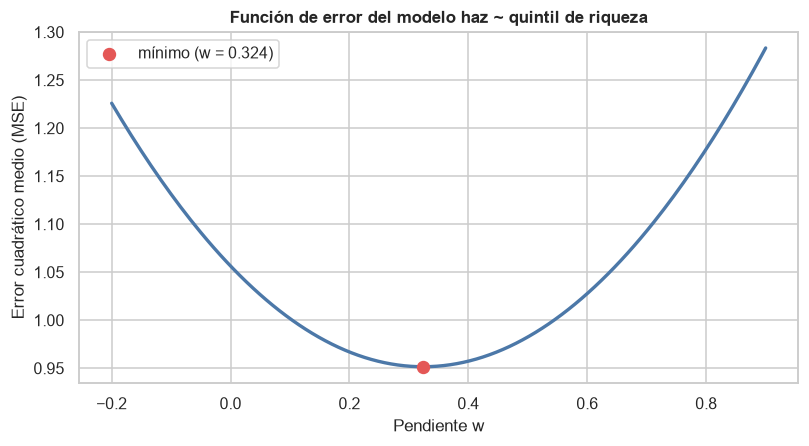

In [34]:
x = ((dr["quintil_riqueza"] - dr["quintil_riqueza"].mean()) / dr["quintil_riqueza"].std()).values
yv = dr["haz"].values
n = len(x)

sk = LinearRegression().fit(x.reshape(-1, 1), yv)
w_opt, b_opt = sk.coef_[0], sk.intercept_
print(f"Solución de scikit-learn: w = {w_opt:.4f}, b = {b_opt:.4f}")

# Función de error: MSE en función de la pendiente w, con el intercepto en su valor óptimo
ws = np.linspace(-0.2, 0.9, 200)
mse_w = [np.mean((w * x + b_opt - yv) ** 2) for w in ws]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(ws, mse_w, color=AZUL, lw=2.2)
ax.scatter([w_opt], [np.mean((w_opt * x + b_opt - yv) ** 2)], color=ROJO, zorder=5, s=60, label=f"mínimo (w = {w_opt:.3f})")
ax.set_xlabel("Pendiente w")
ax.set_ylabel("Error cuadrático medio (MSE)")
ax.set_title("Función de error del modelo haz ~ quintil de riqueza")
ax.legend()
plt.tight_layout()
plt.show()

Descenso de gradiente con tasa 0.3 (primeros 10 pasos):


paso,1,2,3,4,5,6,7,8,9,10
MSE,1.7415,1.0779,0.9718,0.9548,0.9521,0.9516,0.9516,0.9515,0.9515,0.9515
w,0.0000,0.1943,0.2720,0.3031,0.3155,0.3205,0.3225,0.3233,0.3236,0.3237
b,0.0000,-0.4966,-0.6952,-0.7747,-0.8065,-0.8192,-0.8243,-0.8263,-0.8271,-0.8275


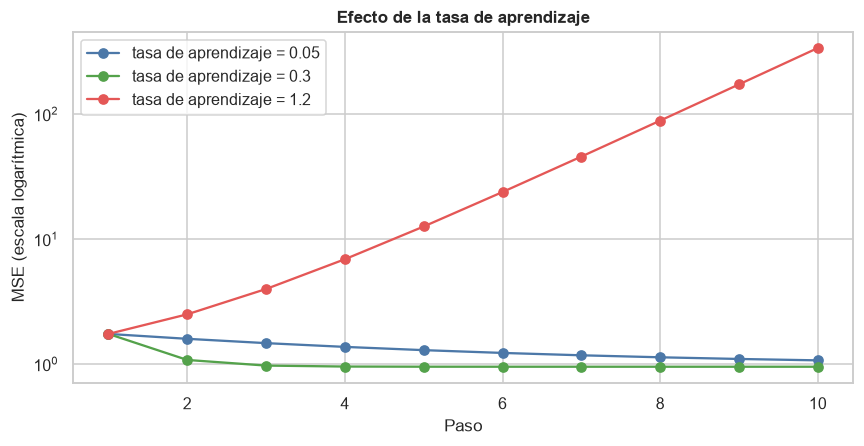

In [35]:
def descenso_gradiente(tasa, pasos=10):
    w, b = 0.0, 0.0
    historial = []
    for paso in range(1, pasos + 1):
        pred = w * x + b
        error = pred - yv
        historial.append({"paso": paso, "MSE": np.mean(error ** 2), "w": w, "b": b})
        gw, gb = (2 / n) * np.sum(error * x), (2 / n) * np.sum(error)
        w, b = w - tasa * gw, b - tasa * gb
    return pd.DataFrame(historial)


gd = {t: descenso_gradiente(t) for t in [0.05, 0.3, 1.2]}
print("Descenso de gradiente con tasa 0.3 (primeros 10 pasos):")
display(gd[0.3].round(4).set_index("paso").T)

fig, ax = plt.subplots(figsize=(8, 4.2))
for t, color in zip(gd, [AZUL, VERDE, ROJO]):
    ax.plot(gd[t]["paso"], gd[t]["MSE"], marker="o", color=color, label=f"tasa de aprendizaje = {t}")
ax.set_yscale("log")
ax.set_xlabel("Paso")
ax.set_ylabel("MSE (escala logarítmica)")
ax.set_title("Efecto de la tasa de aprendizaje")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura:** la curva de error tiene forma de "U" con un único mínimo en w ≈ 0.32, justo donde scikit-learn calcula la pendiente (0.3238). Con tasa 0.3 el descenso llega prácticamente al mínimo en 8 pasos (w = 0.3237, b = −0.8275, MSE ≈ 0.95). Con tasa 0.05 avanza demasiado lento (tras 10 pasos w = 0.21 y el error sigue en 1.07). Con tasa 1.2 **diverge**: cada paso se pasa de largo del mínimo y el error crece (MSE ≈ 338 tras 10 pasos). Es la idea central de la guía: la tasa de aprendizaje no debe ser ni muy pequeña ni muy grande; en XGBoost es el parámetro `learning_rate`.

**Tipo de problema (Semana 03, tabla 3.4).** El proyecto tiene dos formulaciones sobre los mismos datos:

| Objetivo | Aprendizaje | Tipo | Salida |
|---|---|---|---|
| `haz` | supervisado | **regresión** | un número continuo (puntaje Z) |
| `desnutricion_cronica` | supervisado | **clasificación** | una categoría (0 / 1) |

## 11. Regresión lineal sobre los datos crudos (Semana 05)
Se predice el `haz` (continuo). El modelo aprende de datos **sin limpiar**, así que los resultados son la **línea base** que se comparará con los datos limpios.

**División:** 80 % entrenamiento / 20 % prueba con `random_state=42` como en la guía, pero **por conglomerado** (sección 9.3) en lugar de por fila.

In [36]:
X = dr[FEATURES]
y = dr["haz"]
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(X, y, groups=dr["conglomerado"]))
X_tr, X_te, y_tr, y_te = X.iloc[tr], X.iloc[te], y.iloc[tr], y.iloc[te]
print(f"Entrenamiento: {len(tr):,} niños | Prueba: {len(te):,} niños | conglomerados en común: {len(set(dr.conglomerado.iloc[tr]) & set(dr.conglomerado.iloc[te]))}")


def metricas(y_real, y_pred, p):
    n_ = len(y_real)
    mse = mean_squared_error(y_real, y_pred)
    r2 = r2_score(y_real, y_pred)
    return {"MAE": mean_absolute_error(y_real, y_pred), "MSE": mse, "RMSE": np.sqrt(mse), "R²": r2,
            "R² ajustado": 1 - (1 - r2) * (n_ - 1) / (n_ - p - 1)}

Entrenamiento: 14,421 niños | Prueba: 3,602 niños | conglomerados en común: 0


### 11.1 Verificación manual de los coeficientes (mínimos cuadrados)
Antes de usar scikit-learn se calculan β₀ y β₁ con la fórmula, con el ejemplo de la guía (resultado esperado β₀ ≈ 48.67, β₁ ≈ 4.28) y luego con los datos reales.

In [37]:
def mco(x_, y_):
    b1 = np.sum((x_ - x_.mean()) * (y_ - y_.mean())) / np.sum((x_ - x_.mean()) ** 2)
    return y_.mean() - b1 * x_.mean(), b1


# Ejemplo de la guía
horas_doc = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10], dtype=float)
notas_doc = np.array([50, 59, 61, 68, 70, 77, 75, 84, 88, 90], dtype=float)
b0_g, b1_g = mco(horas_doc, notas_doc)
sk_g = LinearRegression().fit(horas_doc.reshape(-1, 1), notas_doc)
print(f"Ejemplo de la guía  → manual: β0 = {b0_g:.2f}, β1 = {b1_g:.2f} | sklearn: β0 = {sk_g.intercept_:.2f}, β1 = {sk_g.coef_[0]:.2f}")

# Datos reales (crudos): haz ~ talla de la madre
x_tr = X_tr["talla_madre_x10"].values.astype(float)
b0_m, b1_m = mco(x_tr, y_tr.values)
simple = LinearRegression().fit(X_tr[["talla_madre_x10"]], y_tr)
print(f"Datos del proyecto  → manual: β0 = {b0_m:.4f}, β1 = {b1_m:.6f} | sklearn: β0 = {simple.intercept_:.4f}, β1 = {simple.coef_[0]:.6f}")
print("¿Coinciden?", np.allclose([b0_m, b1_m], [simple.intercept_, simple.coef_[0]]))

Ejemplo de la guía  → manual: β0 = 48.67, β1 = 4.28 | sklearn: β0 = 48.67, β1 = 4.28
Datos del proyecto  → manual: β0 = -1.3383, β1 = 0.000326 | sklearn: β0 = -1.3383, β1 = 0.000326
¿Coinciden? True


### 11.2 Regresión simple: `haz ~ talla_madre_x10`

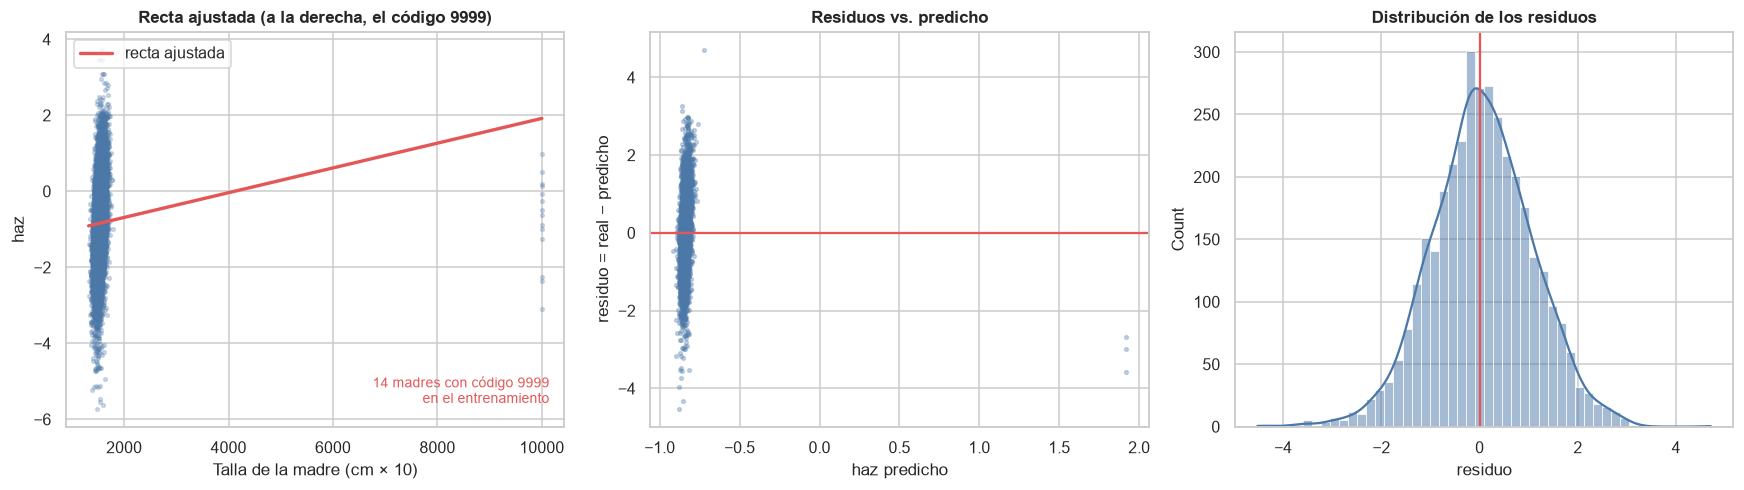

Intercepto = -1.338 | pendiente = 0.00033 (cambio del haz por cada décima de cm)


,MAE,MSE,RMSE,R²,R² ajustado
Regresión simple,0.8089,1.0628,1.0309,0.0028,0.0025


In [38]:
pred_s = simple.predict(X_te[["talla_madre_x10"]])
m_simple = metricas(y_te, pred_s, 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ax = axes[0]
ax.scatter(X_tr["talla_madre_x10"], y_tr, s=6, alpha=0.25, color=AZUL)
xs = np.array([X_tr["talla_madre_x10"].min(), 9999])
ax.plot(xs, simple.intercept_ + simple.coef_[0] * xs, color=ROJO, lw=2.2, label="recta ajustada")
ax.set_xlabel("Talla de la madre (cm × 10)")
ax.set_ylabel("haz")
ax.set_title("Recta ajustada (a la derecha, el código 9999)")
ax.text(0.97, 0.06, f"{int((X_tr['talla_madre_x10'] == 9999).sum())} madres con código 9999\nen el entrenamiento", transform=ax.transAxes,
        ha="right", fontsize=9, color=ROJO)
ax.legend(loc="upper left")

residuo = y_te - pred_s
axes[1].scatter(pred_s, residuo, s=6, alpha=0.3, color=AZUL)
axes[1].axhline(0, color=ROJO, lw=1.5)
axes[1].set_xlabel("haz predicho")
axes[1].set_ylabel("residuo = real − predicho")
axes[1].set_title("Residuos vs. predicho")

sns.histplot(residuo, bins=50, kde=True, color=AZUL, ax=axes[2])
axes[2].axvline(0, color=ROJO, lw=1.5)
axes[2].set_xlabel("residuo")
axes[2].set_title("Distribución de los residuos")
plt.tight_layout()
plt.show()

print(f"Intercepto = {simple.intercept_:.3f} | pendiente = {simple.coef_[0]:.5f} (cambio del haz por cada décima de cm)")
pd.DataFrame([m_simple], index=["Regresión simple"]).round(4)

**Lectura:** con la talla de la madre sola el modelo explica **casi nada** (R² = 0.003, RMSE = 1.031, casi igual que predecir siempre la media, 1.034). No es que la talla no importe (Spearman +0.38): la recta se ajusta con el código 9999 incluido, que la deja casi plana (0.0003 puntos de `haz` por décima de cm). Es la advertencia de la guía hecha realidad: un R² bajo no descarta una variable, hay que mirar los datos. Los residuos tienen forma de campana centrada en 0, pero el modelo trata como "madres de 10 metros" a las que no se midieron. Además, el cálculo manual de mínimos cuadrados coincide con scikit-learn, tanto en el ejemplo de la guía (β₀ = 48.67, β₁ = 4.28) como en los datos del proyecto.

### 11.3 Regresión múltiple: ¿cuánto aporta cada predictor?
Se agregan predictores de uno en uno (Ejercicio 3 de la guía) y se compara **R²** con **R² ajustado**, que penaliza los predictores inútiles. Valores faltantes: mediana.

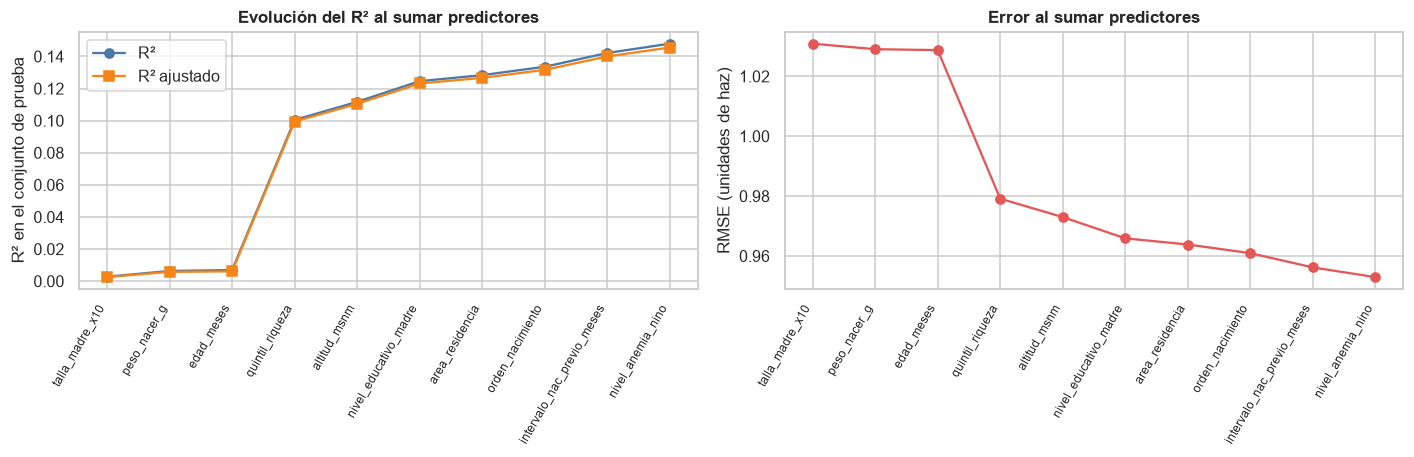

,se agrega,MAE,MSE,RMSE,R²,R² ajustado
predictores,,,,,,
1,talla_madre_x10,0.8089,1.0628,1.0309,0.0028,0.0025
2,peso_nacer_g,0.8074,1.0590,1.0291,0.0064,0.0058
3,edad_meses,0.8068,1.0584,1.0288,0.0070,0.0061
4,quintil_riqueza,0.7653,0.9587,0.9791,0.1005,0.0995
5,altitud_msnm,0.7606,0.9467,0.9730,0.1117,0.1105
6,nivel_educativo_madre,0.7552,0.9330,0.9659,0.1246,0.1232
7,area_residencia,0.7552,0.9290,0.9638,0.1284,0.1267
8,orden_nacimiento,0.7525,0.9234,0.9609,0.1336,0.1316
9,intervalo_nac_previo_meses,0.7491,0.9143,0.9562,0.1422,0.1400


In [39]:
orden_pred = ["talla_madre_x10", "peso_nacer_g", "edad_meses", "quintil_riqueza", "altitud_msnm",
              "nivel_educativo_madre", "area_residencia", "orden_nacimiento", "intervalo_nac_previo_meses", "nivel_anemia_nino"]
filas = []
for k in range(1, len(orden_pred) + 1):
    cols = orden_pred[:k]
    mod = Pipeline([("imp", SimpleImputer(strategy="median")), ("lr", LinearRegression())]).fit(X_tr[cols], y_tr)
    r = metricas(y_te, mod.predict(X_te[cols]), k)
    filas.append({"predictores": k, "se agrega": cols[-1], **r})
secuencia = pd.DataFrame(filas).set_index("predictores")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(secuencia.index, secuencia["R²"], marker="o", color=AZUL, label="R²")
axes[0].plot(secuencia.index, secuencia["R² ajustado"], marker="s", color=NARANJA, label="R² ajustado")
axes[0].set_xticks(secuencia.index)
axes[0].set_xticklabels(secuencia["se agrega"], rotation=60, ha="right", fontsize=8)
axes[0].set_ylabel("R² en el conjunto de prueba")
axes[0].set_title("Evolución del R² al sumar predictores")
axes[0].legend()
axes[1].plot(secuencia.index, secuencia["RMSE"], marker="o", color=ROJO)
axes[1].set_xticks(secuencia.index)
axes[1].set_xticklabels(secuencia["se agrega"], rotation=60, ha="right", fontsize=8)
axes[1].set_ylabel("RMSE (unidades de haz)")
axes[1].set_title("Error al sumar predictores")
plt.tight_layout()
plt.show()
secuencia.round(4)

**Lectura:** cada predictor nuevo mejora el modelo: el R² pasa de 0.003 con la talla de la madre a 0.148 con diez variables, y el RMSE de 1.031 a 0.953. El mayor salto llega con el **quintil de riqueza** (de 0.007 a 0.100): la pobreza es lo que más aporta a la regresión lineal sobre datos crudos. El peso al nacer y la talla aportan poco **en crudo** porque sus códigos especiales los distorsionan. El R² ajustado va casi pegado al R² (0.1456 frente a 0.1480): ningún predictor resulta inútil según la penalización, aunque desde la quinta las ganancias son pequeñas (+0.004 a +0.013 por variable).

### 11.4 Pipeline completo y comparación de modelos
Como en la guía (5.3-5.6), un `ColumnTransformer` trata cada tipo de columna: numéricas con imputación por mediana y categóricas con moda + One-Hot. Se entrenan **tres** modelos con el mismo preprocesamiento: un modelo de referencia que predice siempre la media (`Dummy`), la **regresión lineal** y el **Random Forest** (200 árboles).

In [40]:
numericas = [c for c in FEATURES if c not in CATEG]
preproc = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median"))]), numericas),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEG),
])

modelos = {
    "Referencia (media)": DummyRegressor(strategy="mean"),
    "Regresión lineal": LinearRegression(),
    "Random Forest (200 árboles)": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}
ajustados, preds, filas = {}, {}, []
for nombre, modelo in modelos.items():
    pipe = Pipeline([("prep", preproc), ("model", modelo)]).fit(X_tr, y_tr)
    ajustados[nombre] = pipe
    preds[nombre] = pipe.predict(X_te)
    filas.append({"modelo": nombre, **metricas(y_te, preds[nombre], X_tr.shape[1])})
comparacion = pd.DataFrame(filas).set_index("modelo")
comparacion.round(4)

,MAE,MSE,RMSE,R²,R² ajustado
modelo,,,,,
Referencia (media),0.8119,1.0685,1.0337,-0.0025,-0.0144
Regresión lineal,0.7092,0.8160,0.9033,0.2344,0.2253
Random Forest (200 árboles),0.6683,0.7205,0.8488,0.3239,0.3160


Mejor modelo en el conjunto de prueba: Random Forest (200 árboles)


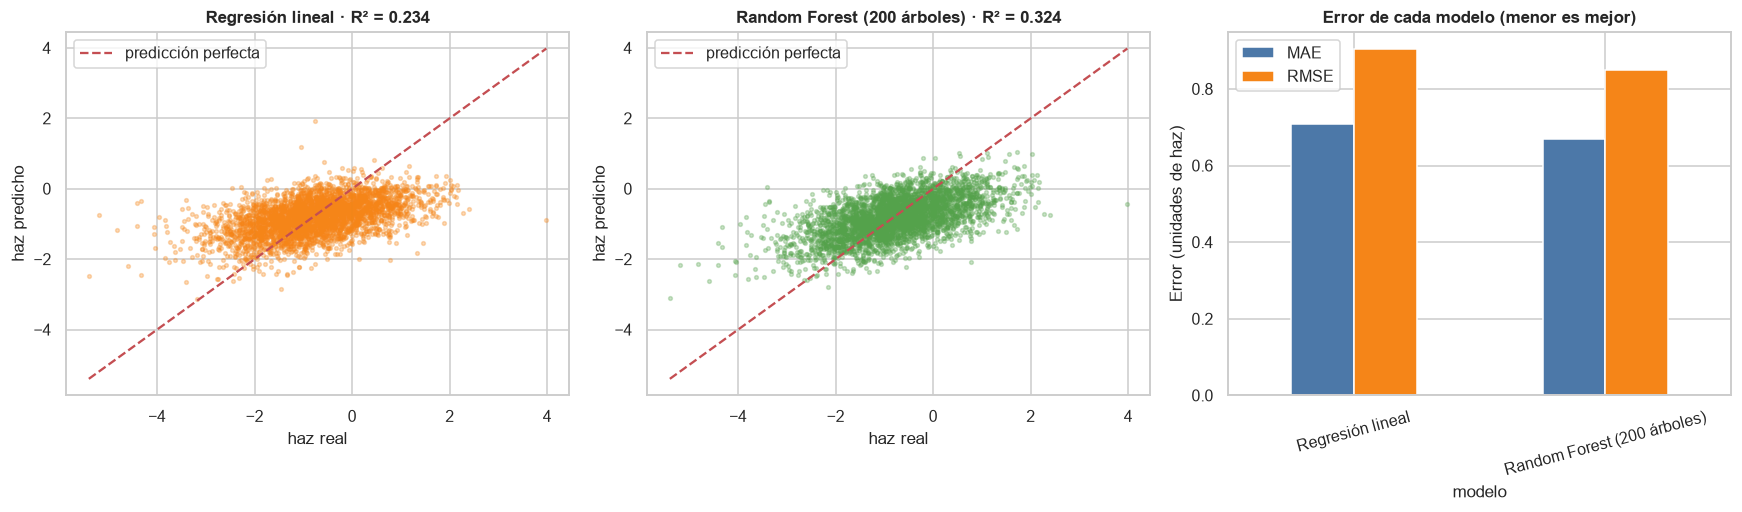

In [41]:
mejor = comparacion["R²"].idxmax()
print("Mejor modelo en el conjunto de prueba:", mejor)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, nombre, color in zip(axes[:2], ["Regresión lineal", "Random Forest (200 árboles)"], [NARANJA, VERDE]):
    ax.scatter(y_te, preds[nombre], s=6, alpha=0.3, color=color)
    lim = [min(y_te.min(), preds[nombre].min()), max(y_te.max(), preds[nombre].max())]
    ax.plot(lim, lim, "r--", lw=1.5, label="predicción perfecta")
    ax.set_xlabel("haz real")
    ax.set_ylabel("haz predicho")
    ax.set_title(f"{nombre} · R² = {r2_score(y_te, preds[nombre]):.3f}")
    ax.legend()

res = comparacion[["MAE", "RMSE"]].drop("Referencia (media)")
res.plot.bar(ax=axes[2], color=[AZUL, NARANJA], rot=15)
axes[2].set_ylabel("Error (unidades de haz)")
axes[2].set_title("Error de cada modelo (menor es mejor)")
plt.tight_layout()
plt.show()

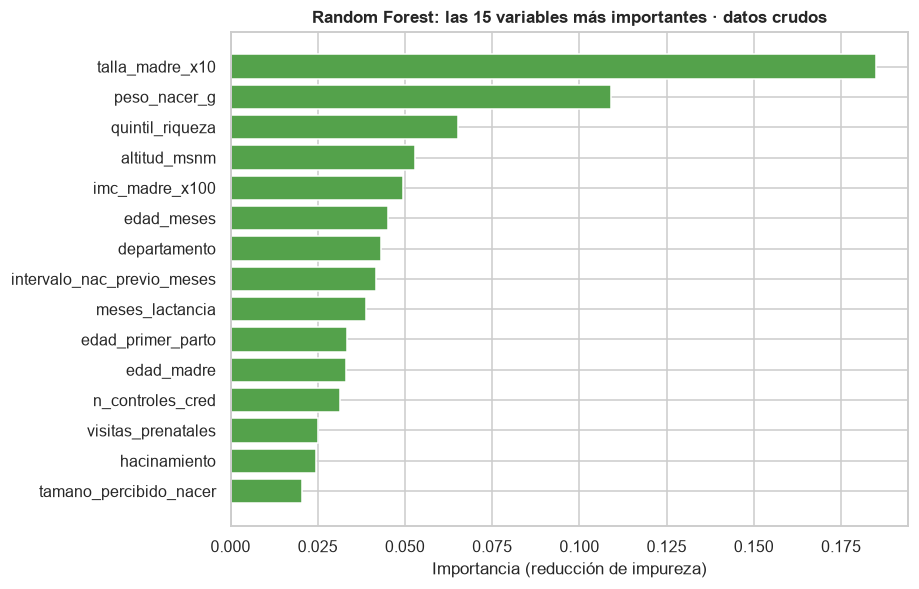

In [42]:
# Importancia de variables del Random Forest, sumando las columnas One-Hot de cada variable original
rf = ajustados["Random Forest (200 árboles)"]
nombres = rf.named_steps["prep"].get_feature_names_out()
imp_cols = pd.Series(rf.named_steps["model"].feature_importances_, index=nombres)


def original(nombre):
    base = nombre.split("__", 1)[1]
    for c in CATEG:
        if base.startswith(c + "_"):
            return c
    return base


imp_var = imp_cols.groupby(original).sum().sort_values(ascending=False)
top = imp_var.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(top.index, top.values, color=VERDE)
ax.set_xlabel("Importancia (reducción de impureza)")
ax.set_title("Random Forest: las 15 variables más importantes · datos crudos")
plt.tight_layout()
plt.show()

**Lectura:** con las 42 variables y el mismo preprocesamiento, la referencia (la media) tiene R² ≈ 0, la regresión lineal sube a 0.234 (RMSE 0.903) y el Random Forest a 0.324 (RMSE 0.849, MAE 0.668): el bosque reduce ≈ 18 % el error de la referencia. Gana por dos razones: capta relaciones no lineales (como la edad, que sube y baja) y **tolera los códigos especiales** (puede aislarlos en una rama), algo que la regresión lineal no puede. En el gráfico real vs. predicho ambos modelos "aplanan" la nube y subestiman los extremos, típico de un R² moderado. La importancia del bosque (talla de la madre, peso al nacer, riqueza, altitud, IMC) coincide con las correlaciones. Este R² ≈ 0.32 es la **línea base** que hay que superar con los datos limpios.

## 12. Hallazgos y plan de limpieza

In [43]:
hallazgos = pd.DataFrame([
    ("Códigos especiales", f"{len(codigos_tabla)} variables con códigos tipo 9996-9999, 98 y 8 que parecen datos reales", "Convertir a NaN variable por variable (tabla del diccionario)"),
    ("Valores vacíos", f"{int((tabla_vacios['vacíos'] > 0).sum())} features con vacíos; los más altos son por diseño (edad, primogénitos)", "Conservar el NaN (XGBoost lo maneja); imputar por mediana/moda solo para regresión lineal"),
    ("Objetivo sin dato", f"{len(df) - len(dr):,} niños sin puntaje Z válido", "Eliminarlos antes de entrenar"),
    ("Duplicados y grupos", f"{dup_exactas} filas duplicadas; {int(len(df) - df['caseid'].nunique()):,} niños tienen un hermano en la muestra", "No eliminar; dividir por conglomerado"),
    ("Preguntas del hijo menor", f"visitas_prenatales y hierro_embarazo vacíos en {df.loc[~es_menor, 'visitas_prenatales'].isna().mean():.0%} de los niños con un hermano menor", "Dejar NaN (no imputar): no es un dato perdido sino una pregunta que no se hizo"),
    ("Código fuera del diccionario", "cloro_residual_agua tiene el código 6 (≈ 1 200 casos)", "Pasarlo a NaN"),
    ("Escala distinta", "peso (g), altitud (m), edades (años y meses)", "Escalar solo para regresión lineal; los árboles no lo necesitan"),
    ("Variables en escala falsa", "Vacunas 0-3, categóricas con códigos arbitrarios", "Vacunas a 0/1; categóricas como category o One-Hot"),
    ("División train/test", f"Al azar vs. por conglomerado: R² {medio.loc['Al azar por niño', ('R² (regresión)', 'mean')]:.3f} vs. {medio.loc['Por conglomerado', ('R² (regresión)', 'mean')]:.3f} (sin fuga apreciable)", "GroupShuffleSplit por conglomerado, por prudencia"),
    ("Relación no lineal con la edad", "La prevalencia sube hasta los 12-23 meses y luego baja", "Usar árboles/XGBoost; en regresión lineal considerar la edad por tramos"),
    ("Clases desbalanceadas", f"{PREV:.1f} % de desnutridos", "scale_pos_weight; evaluar con AUC-PR, recall y F1"),
], columns=["tema", "hallazgo en los datos crudos", "acción en la limpieza (notebook 03)"])
hallazgos

,tema,hallazgo en los datos crudos,acción en la limpieza (notebook 03)
0,Códigos especiales,"20 variables con códigos tipo 9996-9999, 98 y 8 que parecen datos reales",Convertir a NaN variable por variable (tabla del diccionario)
1,Valores vacíos,"17 features con vacíos; los más altos son por diseño (edad, primogénitos)",Conservar el NaN (XGBoost lo maneja); imputar por mediana/moda solo para reg...
2,Objetivo sin dato,818 niños sin puntaje Z válido,Eliminarlos antes de entrenar
3,Duplicados y grupos,"0 filas duplicadas; 1,908 niños tienen un hermano en la muestra",No eliminar; dividir por conglomerado
4,Preguntas del hijo menor,visitas_prenatales y hierro_embarazo vacíos en 81% de los niños con un herma...,Dejar NaN (no imputar): no es un dato perdido sino una pregunta que no se hizo
5,Código fuera del diccionario,cloro_residual_agua tiene el código 6 (≈ 1 200 casos),Pasarlo a NaN
6,Escala distinta,"peso (g), altitud (m), edades (años y meses)",Escalar solo para regresión lineal; los árboles no lo necesitan
7,Variables en escala falsa,"Vacunas 0-3, categóricas con códigos arbitrarios",Vacunas a 0/1; categóricas como category o One-Hot
8,División train/test,Al azar vs. por conglomerado: R² 0.338 vs. 0.339 (sin fuga apreciable),"GroupShuffleSplit por conglomerado, por prudencia"
9,Relación no lineal con la edad,La prevalencia sube hasta los 12-23 meses y luego baja,Usar árboles/XGBoost; en regresión lineal considerar la edad por tramos


### Línea base para comparar después
Estos resultados se vuelven a calcular en el notebook 04 con los datos limpios.

In [44]:
linea_base = pd.DataFrame({
    "R² regresión simple (talla materna)": [m_simple["R²"]],
    "R² regresión lineal (42 variables)": [comparacion.loc["Regresión lineal", "R²"]],
    "R² Random Forest": [comparacion.loc["Random Forest (200 árboles)", "R²"]],
    "RMSE Random Forest": [comparacion.loc["Random Forest (200 árboles)", "RMSE"]],
}, index=["datos crudos"]).round(4)
linea_base

,R² regresión simple (talla materna),R² regresión lineal (42 variables),R² Random Forest,RMSE Random Forest
datos crudos,0.0028,0.2344,0.3239,0.8488


**Siguiente notebook (03):** limpieza paso a paso: códigos especiales a `NaN`, recodificaciones, filtrado de niños sin objetivo, variables derivadas, codificación y división por conglomerado.